In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from sqlalchemy import text
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
_25_setembro_trainning_data =pd.concat([pd.read_csv('25_SETEMBRO_DATA/data_2020Q1.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2020Q2.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2020Q3.csv'),pd.read_csv('25_SETEMBRO_DATA/data_2020Q4.csv'),
                           pd.read_csv('25_SETEMBRO_DATA/data_2021Q1.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2021Q2.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2021Q3.csv'),pd.read_csv('25_SETEMBRO_DATA/data_2021Q4.csv'),
                           pd.read_csv('25_SETEMBRO_DATA/data_2022Q1.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2022Q2.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2022Q3.csv'),pd.read_csv('25_SETEMBRO_DATA/data_2022Q4.csv'),
                           pd.read_csv('25_SETEMBRO_DATA/data_2023Q1.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2023Q2.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2023Q3.csv'),pd.read_csv('25_SETEMBRO_DATA/data_2023Q4.csv')])

_1_maio_trainning_data = pd.concat([pd.read_csv('1_MAIO/data_2020Q1.csv'), pd.read_csv('1_MAIO/data_2020Q2.csv'), pd.read_csv('1_MAIO/data_2020Q3.csv'),pd.read_csv('1_MAIO/data_2020Q4.csv'),
                           pd.read_csv('1_MAIO/data_2021Q1.csv'), pd.read_csv('1_MAIO/data_2021Q2.csv'), pd.read_csv('1_MAIO/data_2021Q3.csv'),pd.read_csv('1_MAIO/data_2021Q4.csv'),
                           pd.read_csv('1_MAIO/data_2022Q1.csv'), pd.read_csv('1_MAIO/data_2022Q2.csv'), pd.read_csv('1_MAIO/data_2022Q3.csv'),pd.read_csv('1_MAIO/data_2022Q4.csv'),
                           pd.read_csv('1_MAIO/data_2023Q1.csv'), pd.read_csv('1_MAIO/data_2023Q2.csv'), pd.read_csv('1_MAIO/data_2023Q3.csv'),pd.read_csv('1_MAIO/data_2023Q4.csv')])

_25_setembro_calibration_data_fit =pd.concat([pd.read_csv('25_SETEMBRO_DATA/data_2024Q1.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2024Q2.csv')])
_25_setembro_calibration_data_test =pd.concat([pd.read_csv('25_SETEMBRO_DATA/data_2024Q3.csv'), pd.read_csv('25_SETEMBRO_DATA/data_2024Q4.csv')])

_1_maio_calibration_data_fit = pd.concat([pd.read_csv('1_MAIO/data_2024Q1.csv'), pd.read_csv('1_MAIO/data_2024Q2.csv')])
_1_maio_calibration_data_test = pd.concat([pd.read_csv('1_MAIO/data_2024Q3.csv'), pd.read_csv('1_MAIO/data_2024Q4.csv')])

In [3]:
_25_setembro_trainning_data['hf_code'] = 200291
_1_maio_trainning_data['hf_code'] = 200966

_25_setembro_calibration_data_fit['hf_code'] = 200291
_25_setembro_calibration_data_test['hf_code'] = 200291

_1_maio_calibration_data_fit['hf_code'] = 200966
_1_maio_calibration_data_test['hf_code'] = 200966

trainning_data_ = pd.concat([_25_setembro_trainning_data,_1_maio_trainning_data])

calibration_data_fit_ = pd.concat([_25_setembro_calibration_data_fit,_1_maio_calibration_data_fit])
calibration_data_test_ = pd.concat([_25_setembro_calibration_data_test,_1_maio_calibration_data_test])

In [4]:
trainning_data_.info()

<class 'pandas.core.frame.DataFrame'>
Index: 263144 entries, 0 to 7260
Data columns (total 33 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   patient_id                              263144 non-null  int64  
 1   age                                     263144 non-null  int64  
 2   sex                                     263144 non-null  object 
 3   level_of_education                      183635 non-null  float64
 4   reason_of_visit                         185978 non-null  float64
 5   last_appointment_date                   262861 non-null  object 
 6   first_who_stage                         247812 non-null  float64
 7   last_who_stage                          255182 non-null  float64
 8   first_viral_load                        15910 non-null   float64
 9   last_viral_load                         63264 non-null   float64
 10  treatment_adhesion                      222090 non-

In [5]:
trainning_data_.isnull().sum()

patient_id                                     0
age                                            0
sex                                            0
level_of_education                         79509
reason_of_visit                            77166
last_appointment_date                        283
first_who_stage                            15332
last_who_stage                              7962
first_viral_load                          247234
last_viral_load                           199880
treatment_adhesion                         41054
hiv_disclose                               79960
phycological_factors                      235711
art_start_date                                 0
first_art_regimen                          84025
last_art_regimen                            3514
art_line                                   20082
art_line_change                           195811
art_line_change_reason                    258990
art_status_change                         261975
side_effects        

In [6]:
def clean_invalid_date(data):
    data['last_appointment_date'] = pd.to_datetime(data['last_appointment_date'], errors='coerce')
    data['next_drug_pickup_date'] = pd.to_datetime(data['next_drug_pickup_date'], errors='coerce')
    data['art_start_date'] = pd.to_datetime(data['art_start_date'], errors='coerce')

    return data

In [7]:
trainning_data = clean_invalid_date(trainning_data_)
calibration_data_fit = clean_invalid_date(calibration_data_fit_)
calibration_data_test = clean_invalid_date(calibration_data_test_)

In [8]:
trainning_data.isnull().sum()

patient_id                                     0
age                                            0
sex                                            0
level_of_education                         79509
reason_of_visit                            77166
last_appointment_date                        283
first_who_stage                            15332
last_who_stage                              7962
first_viral_load                          247234
last_viral_load                           199880
treatment_adhesion                         41054
hiv_disclose                               79960
phycological_factors                      235711
art_start_date                             11193
first_art_regimen                          84025
last_art_regimen                            3514
art_line                                   20082
art_line_change                           195811
art_line_change_reason                    258990
art_status_change                         261975
side_effects        

In [9]:
trainning_data.info()
calibration_data_fit.info()
calibration_data_test.info()


<class 'pandas.core.frame.DataFrame'>
Index: 263144 entries, 0 to 7260
Data columns (total 33 columns):
 #   Column                                  Non-Null Count   Dtype         
---  ------                                  --------------   -----         
 0   patient_id                              263144 non-null  int64         
 1   age                                     263144 non-null  int64         
 2   sex                                     263144 non-null  object        
 3   level_of_education                      183635 non-null  float64       
 4   reason_of_visit                         185978 non-null  float64       
 5   last_appointment_date                   262861 non-null  datetime64[ns]
 6   first_who_stage                         247812 non-null  float64       
 7   last_who_stage                          255182 non-null  float64       
 8   first_viral_load                        15910 non-null   float64       
 9   last_viral_load                         6326

In [10]:
# excluse patients with less than 18 years old
trainning_data = trainning_data.loc[trainning_data['age']>= 18]
calibration_data_fit = calibration_data_fit.loc[calibration_data_fit['age']>= 18]
calibration_data_test = calibration_data_test.loc[calibration_data_test['age']>= 18]


In [11]:
trainning_data.info()
calibration_data_fit.info()
calibration_data_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 245991 entries, 0 to 7260
Data columns (total 33 columns):
 #   Column                                  Non-Null Count   Dtype         
---  ------                                  --------------   -----         
 0   patient_id                              245991 non-null  int64         
 1   age                                     245991 non-null  int64         
 2   sex                                     245991 non-null  object        
 3   level_of_education                      175865 non-null  float64       
 4   reason_of_visit                         172843 non-null  float64       
 5   last_appointment_date                   245718 non-null  datetime64[ns]
 6   first_who_stage                         231630 non-null  float64       
 7   last_who_stage                          238574 non-null  float64       
 8   first_viral_load                        10644 non-null   float64       
 9   last_viral_load                         5997

In [12]:
calibration_data_fit = calibration_data_fit[~(calibration_data_fit['patient_id'].isin(trainning_data['patient_id']) & calibration_data_fit['hf_code'].isin(trainning_data['hf_code']))]
calibration_data_test = calibration_data_test[~(calibration_data_test['patient_id'].isin(trainning_data['patient_id']) & calibration_data_test['hf_code'].isin(trainning_data['hf_code']))]

In [13]:
trainning_data.columns

Index(['patient_id', 'age', 'sex', 'level_of_education', 'reason_of_visit',
       'last_appointment_date', 'first_who_stage', 'last_who_stage',
       'first_viral_load', 'last_viral_load', 'treatment_adhesion',
       'hiv_disclose', 'phycological_factors', 'art_start_date',
       'first_art_regimen', 'last_art_regimen', 'art_line', 'art_line_change',
       'art_line_change_reason', 'art_status_change', 'side_effects',
       'type_of_dispensation', 'method_of_dispensation',
       'next_drug_pickup_date', 'predict_date', 'target',
       'number_of_followup_appointments',
       'number_of_missed_followup_appointments', 'appointment_attendance_rate',
       'number_of_drug_pickup', 'number_of_missed_drug_pickup',
       'drug_pickup_attendance_rate', 'hf_code'],
      dtype='object')

In [14]:
# Filling missing values with -99999 and converting to int
numeric_columns = ['level_of_education', 'reason_of_visit', 'first_who_stage', 'last_who_stage',
       'first_viral_load', 'last_viral_load', 'treatment_adhesion',
       'hiv_disclose', 'phycological_factors','first_art_regimen', 'last_art_regimen', 
       'art_line', 'art_line_change','art_line_change_reason', 'art_status_change', 
       'side_effects','type_of_dispensation', 'method_of_dispensation']

def fill_missing_and_convert_to_int(df, columns):
    for column in columns:
        df[column] = df[column].fillna(-99999).astype(int)
    return df

In [15]:
# Converting date columns to datetime format
date_columns = ['last_appointment_date', 'next_drug_pickup_date', 'art_start_date', 'predict_date']

def convert_date_columns_to_datetime(df, date_columns):
    for column in date_columns:
        df[column] = pd.to_datetime(df[column], errors='coerce')
    return df

In [16]:
# Computing the number of days since last appointment, days until scheduled drug pickup, and days since ART start

def compute_days_since_dates(df):
    
    df['last_appointment_date'] = df['last_appointment_date'].fillna(df['predict_date'])
    df['art_start_date'] = df['art_start_date'].fillna(df['predict_date'])
    
    df['number_of_days_since_last_appointment'] = (df['predict_date'] - df['last_appointment_date']).dt.days
    df['number_of_days_since_art_start'] = (df['predict_date'] - df['art_start_date']).dt.days
    df['number_of_days_until_scheduled_drug_pickup'] = (df['predict_date'] - df['next_drug_pickup_date']).dt.days
    
    return df

In [17]:
# Converting 'sex' column to binary format
def convert_sex_column_to_binary(df):
    df['sex'] = df['sex'].map({'M': 0, 'F': 1}).astype(int)
    return df

In [18]:
#Separating features and target variable
def separate_predict_features_and_target(df):
    df = df[['age', 'sex', 'level_of_education', 'reason_of_visit',
       'number_of_days_since_last_appointment', 'first_who_stage', 'last_who_stage',
       'first_viral_load', 'last_viral_load', 'treatment_adhesion',
       'hiv_disclose', 'phycological_factors', 'number_of_days_since_art_start',
       'first_art_regimen', 'last_art_regimen', 'art_line', 'art_line_change',
       'art_line_change_reason', 'art_status_change', 'side_effects',
       'type_of_dispensation', 'method_of_dispensation',
       'number_of_days_until_scheduled_drug_pickup',
       'number_of_followup_appointments',
       'number_of_missed_followup_appointments', 'appointment_attendance_rate',
       'number_of_drug_pickup', 'number_of_missed_drug_pickup',
       'drug_pickup_attendance_rate', 'target']]
    return df

In [19]:
trainning_data

,patient_id,age,sex,level_of_education,reason_of_visit,last_appointment_date,first_who_stage,last_who_stage,first_viral_load,last_viral_load,...,next_drug_pickup_date,predict_date,target,number_of_followup_appointments,number_of_missed_followup_appointments,appointment_attendance_rate,number_of_drug_pickup,number_of_missed_drug_pickup,drug_pickup_attendance_rate,hf_code
0,420,18,M,1447.0,1115.0,2019-12-09,1204.0,1205.0,12667.0,NaN,...,2020-01-09,2020-01-01,1,3,1,0.67,42,2,0.95,200291
1,421,45,F,NaN,NaN,2019-08-28,NaN,1206.0,NaN,NaN,...,2020-02-21,2020-01-01,0,30,10,0.67,71,10,0.86,200291
2,424,39,M,NaN,NaN,2019-06-13,1206.0,1206.0,NaN,NaN,...,2020-02-27,2020-01-01,0,17,2,0.88,18,1,0.94,200291
3,429,54,M,NaN,NaN,2019-09-05,NaN,1206.0,NaN,NaN,...,2020-03-04,2020-01-01,0,10,6,0.40,31,7,0.77,200291
4,433,31,M,NaN,1115.0,2019-06-05,1204.0,1206.0,31300.0,5227.0,...,2020-02-17,2020-01-01,0,24,12,0.50,36,1,0.97,200291
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7256,30185,20,F,NaN,NaN,2023-09-29,1204.0,1204.0,NaN,NaN,...,2023-10-29,2023-10-01,0,1,0,1.00,1,0,1.00,200966
7257,30240,26,F,NaN,NaN,2023-09-05,1204.0,1204.0,NaN,NaN,...,2023-10-05,2023-10-01,0,1,0,1.00,1,0,1.00,200966
7258,30344,29,F,NaN,NaN,2023-09-21,1204.0,1204.0,NaN,NaN,...,2023-10-23,2023-10-01,1,1,0,1.00,1,0,1.00,200966
7259,30924,23,F,NaN,NaN,2023-09-27,1204.0,1204.0,NaN,NaN,...,2023-10-27,2023-10-01,0,1,0,1.00,1,0,1.00,200966


In [20]:
trainning_data['target'].value_counts()

target
0    225768
1     20223
Name: count, dtype: int64

In [21]:
trainning_data = fill_missing_and_convert_to_int(trainning_data, numeric_columns)
trainning_data = convert_date_columns_to_datetime(trainning_data, date_columns)
trainning_data = convert_sex_column_to_binary(trainning_data)
trainning_data = compute_days_since_dates(trainning_data)
trainning_data = separate_predict_features_and_target(trainning_data)

/var/folders/rk/n08shbd567x6xy04n480f5k80000gn/T/ipykernel_24419/2264751916.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = df[column].fillna(-99999).astype(int)
/var/folders/rk/n08shbd567x6xy04n480f5k80000gn/T/ipykernel_24419/2264751916.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = df[column].fillna(-99999).astype(int)
/var/folders/rk/n08shbd567x6xy04n480f5k80000gn/T/ipykernel_24419/2264751916.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a s

In [22]:
trainning_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 245991 entries, 0 to 7260
Data columns (total 30 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   age                                         245991 non-null  int64  
 1   sex                                         245991 non-null  int64  
 2   level_of_education                          245991 non-null  int64  
 3   reason_of_visit                             245991 non-null  int64  
 4   number_of_days_since_last_appointment       245991 non-null  int64  
 5   first_who_stage                             245991 non-null  int64  
 6   last_who_stage                              245991 non-null  int64  
 7   first_viral_load                            245991 non-null  int64  
 8   last_viral_load                             245991 non-null  int64  
 9   treatment_adhesion                          245991 non-null  int64  
 10  hiv

In [23]:
calibration_data_fit = fill_missing_and_convert_to_int(calibration_data_fit, numeric_columns)
calibration_data_fit = convert_date_columns_to_datetime(calibration_data_fit, date_columns)
calibration_data_fit = convert_sex_column_to_binary(calibration_data_fit)
calibration_data_fit = compute_days_since_dates(calibration_data_fit)
calibration_data_fit = separate_predict_features_and_target(calibration_data_fit)

calibration_data_test = fill_missing_and_convert_to_int(calibration_data_test, numeric_columns)
calibration_data_test = convert_date_columns_to_datetime(calibration_data_test, date_columns)
calibration_data_test = convert_sex_column_to_binary(calibration_data_test)
calibration_data_test = compute_days_since_dates(calibration_data_test)
calibration_data_test = separate_predict_features_and_target(calibration_data_test)

In [24]:
calibration_data_fit.info()
calibration_data_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1490 entries, 56 to 7482
Data columns (total 30 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   age                                         1490 non-null   int64  
 1   sex                                         1490 non-null   int64  
 2   level_of_education                          1490 non-null   int64  
 3   reason_of_visit                             1490 non-null   int64  
 4   number_of_days_since_last_appointment       1490 non-null   int64  
 5   first_who_stage                             1490 non-null   int64  
 6   last_who_stage                              1490 non-null   int64  
 7   first_viral_load                            1490 non-null   int64  
 8   last_viral_load                             1490 non-null   int64  
 9   treatment_adhesion                          1490 non-null   int64  
 10  hiv_disclose    

In [25]:
trainning_data['target'].value_counts(normalize=False)

target
0    225768
1     20223
Name: count, dtype: int64

Text(0, 0.5, 'Count')

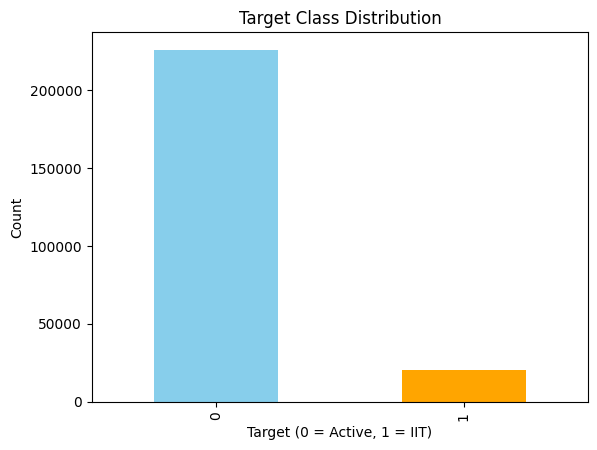

In [26]:
imbalance = trainning_data["target"].value_counts().plot(kind="bar", color=["skyblue", "orange"])
imbalance.set_title("Target Class Distribution")
imbalance.set_xlabel("Target (0 = Active, 1 = IIT)")
imbalance.set_ylabel("Count")


array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'level_of_education'}>,
        <Axes: title={'center': 'reason_of_visit'}>,
        <Axes: title={'center': 'number_of_days_since_last_appointment'}>],
       [<Axes: title={'center': 'first_who_stage'}>,
        <Axes: title={'center': 'last_who_stage'}>,
        <Axes: title={'center': 'first_viral_load'}>,
        <Axes: title={'center': 'last_viral_load'}>,
        <Axes: title={'center': 'treatment_adhesion'}>],
       [<Axes: title={'center': 'hiv_disclose'}>,
        <Axes: title={'center': 'phycological_factors'}>,
        <Axes: title={'center': 'number_of_days_since_art_start'}>,
        <Axes: title={'center': 'first_art_regimen'}>,
        <Axes: title={'center': 'last_art_regimen'}>],
       [<Axes: title={'center': 'art_line'}>,
        <Axes: title={'center': 'art_line_change'}>,
        <Axes: title={'center': 'art_line_change_reason'}>,
        <Axes: title={'cent

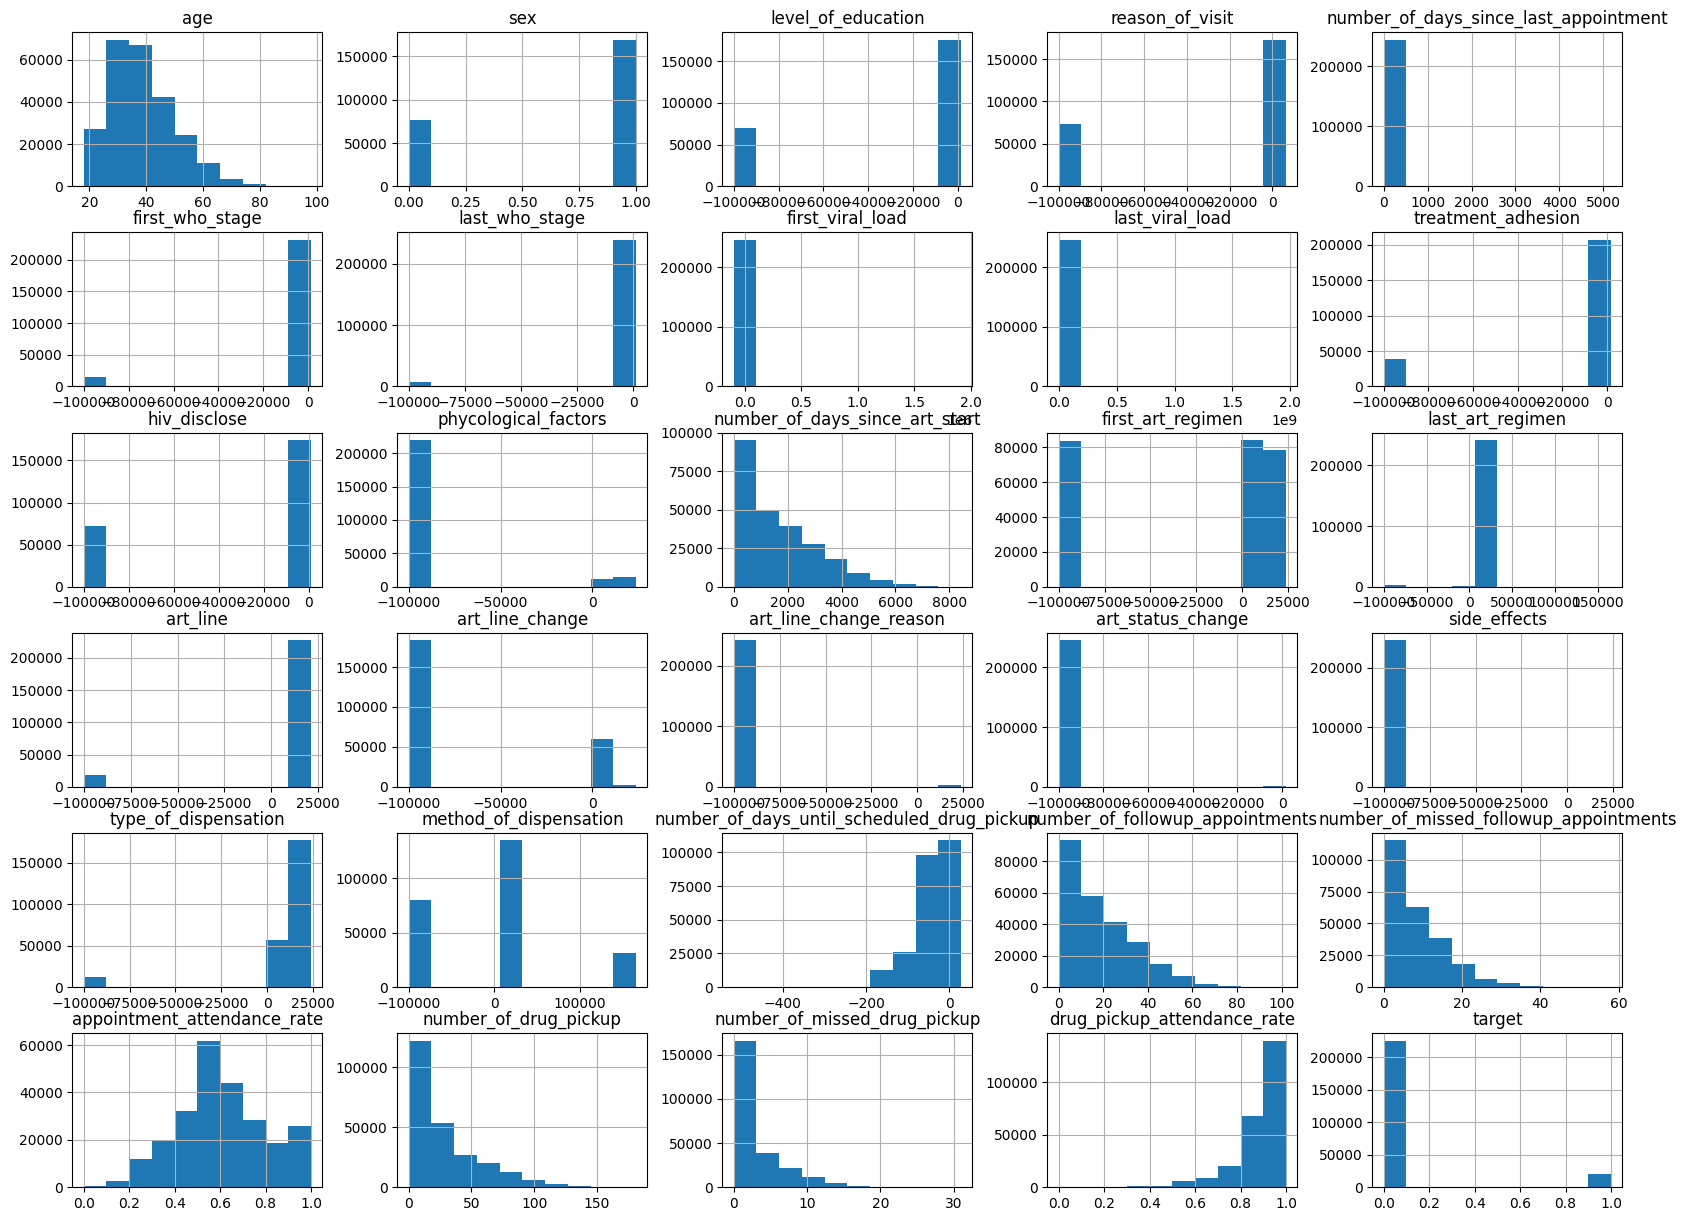

In [27]:
trainning_data.hist(figsize=(20, 15))

In [28]:
trainning_data.columns

Index(['age', 'sex', 'level_of_education', 'reason_of_visit',
       'number_of_days_since_last_appointment', 'first_who_stage',
       'last_who_stage', 'first_viral_load', 'last_viral_load',
       'treatment_adhesion', 'hiv_disclose', 'phycological_factors',
       'number_of_days_since_art_start', 'first_art_regimen',
       'last_art_regimen', 'art_line', 'art_line_change',
       'art_line_change_reason', 'art_status_change', 'side_effects',
       'type_of_dispensation', 'method_of_dispensation',
       'number_of_days_until_scheduled_drug_pickup',
       'number_of_followup_appointments',
       'number_of_missed_followup_appointments', 'appointment_attendance_rate',
       'number_of_drug_pickup', 'number_of_missed_drug_pickup',
       'drug_pickup_attendance_rate', 'target'],
      dtype='object')

<Axes: >

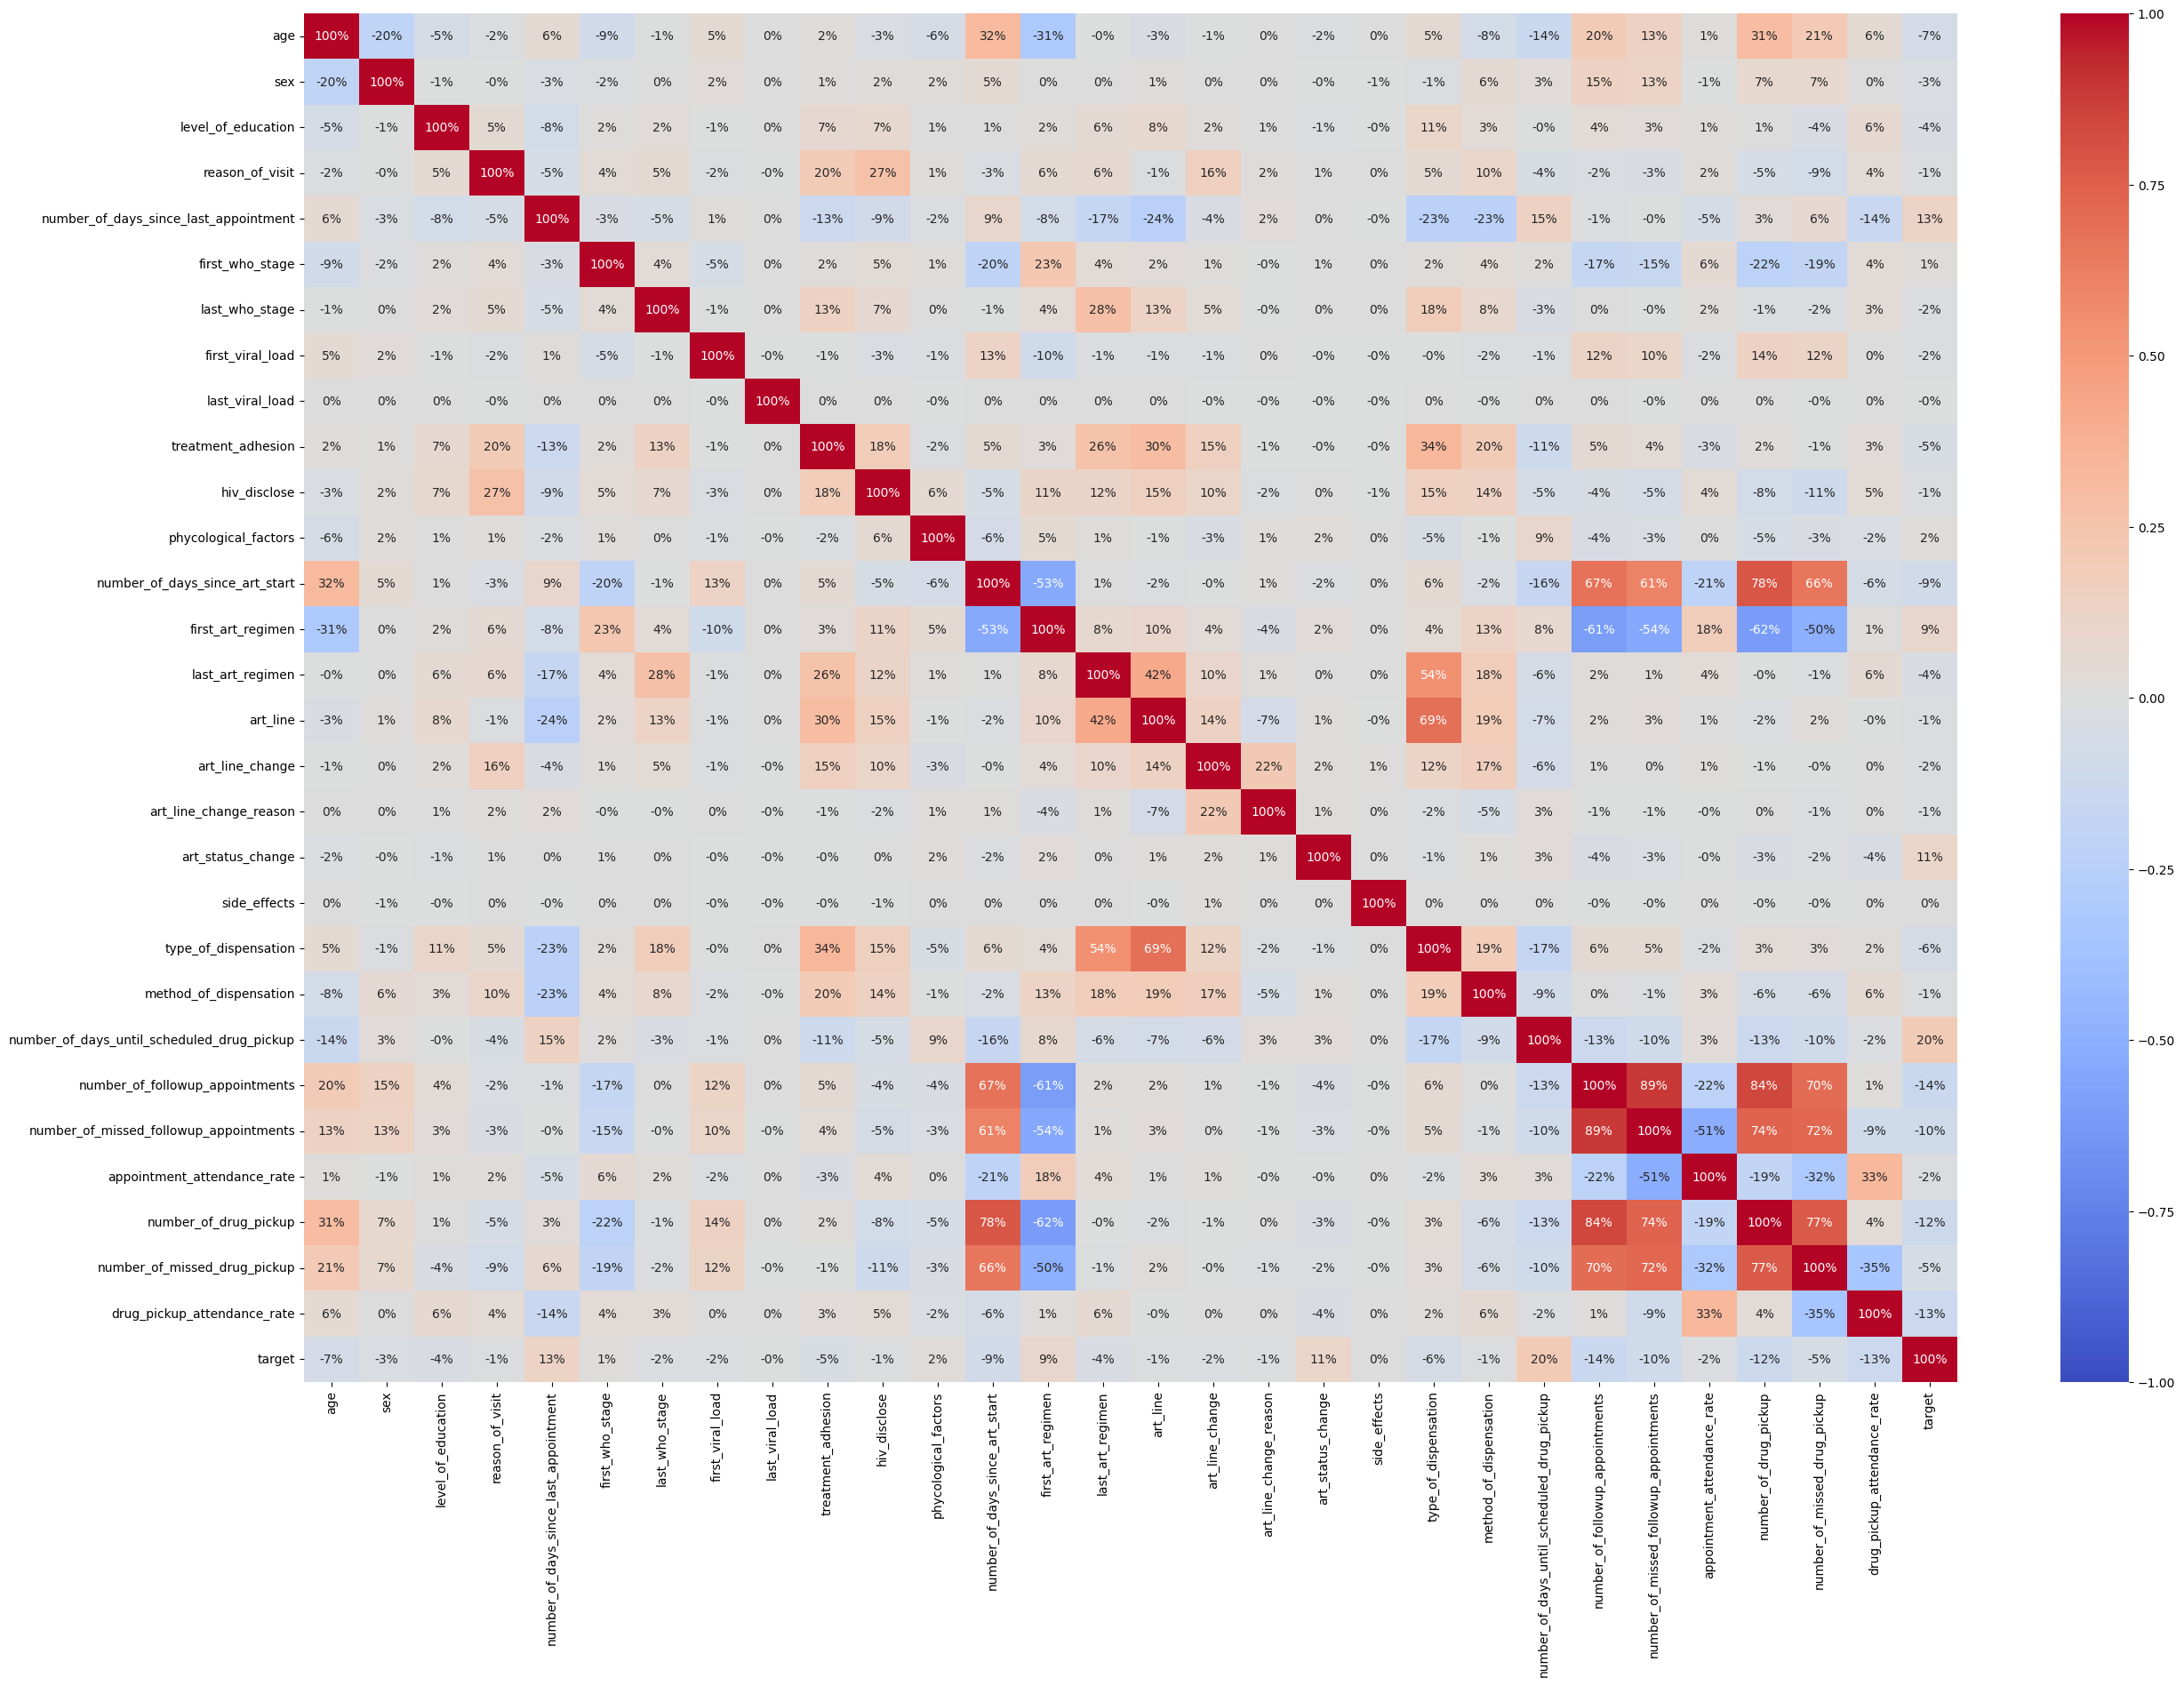

In [29]:
plt.figure(figsize=(30,20))
sns.heatmap(trainning_data.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.0%')

In [30]:
calibration_data_fit['target'].value_counts(normalize=False)

target
0    1157
1     333
Name: count, dtype: int64

In [31]:
calibration_data_test['target'].value_counts(normalize=False)

target
0    2215
1     614
Name: count, dtype: int64

In [32]:
# Importing predictions models
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
import numpy as np

In [33]:
# Random Forest Classifier (Baseline Model)
rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_model.fit(trainning_data.drop('target', axis=1), trainning_data['target'])

rf_calibrated_model = CalibratedClassifierCV(rf_model, method='isotonic', cv='prefit')
rf_calibrated_model.fit(calibration_data_fit.drop('target', axis=1), calibration_data_fit['target'])

CalibratedClassifierCV(cv='prefit',
                       estimator=RandomForestClassifier(n_jobs=-1,
                                                        random_state=42),
                       method='isotonic')

In [34]:
# Random Forest with SMOTE and Calibration
rf_model_pipeline = Pipeline([
    ('somote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42, n_jobs=-1))
])

rf_model_pipeline.fit(trainning_data.drop('target', axis=1), trainning_data['target'])

rf_calibrated_model_sm = CalibratedClassifierCV(rf_model_pipeline, method='isotonic', cv='prefit')
rf_calibrated_model_sm.fit(calibration_data_fit.drop('target', axis=1), calibration_data_fit['target'])

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('somote',
                                                  SMOTE(random_state=42)),
                                                 ('model',
                                                  RandomForestClassifier(n_jobs=-1,
                                                                         random_state=42))]),
                       method='isotonic')

In [35]:
# Gradient Boosting Classifier (Baseline Model)
gboost_model = Pipeline([
    ('scalar', StandardScaler()),
    ('model', GradientBoostingClassifier(random_state=42))
])

gboost_model = GradientBoostingClassifier(random_state=42)
gboost_model.fit(trainning_data.drop('target', axis=1), trainning_data['target'])

gboost_calibrated_model = CalibratedClassifierCV(gboost_model, method='isotonic', cv='prefit')
gboost_calibrated_model.fit(calibration_data_fit.drop('target', axis=1), calibration_data_fit['target'])

CalibratedClassifierCV(cv='prefit',
                       estimator=GradientBoostingClassifier(random_state=42),
                       method='isotonic')

In [36]:
# Gradient Boosting with SMOTE and Calibration
gboost_pipeline = Pipeline([
    ('scalar', StandardScaler()),
    ('somote', SMOTE(random_state=42)),
    ('model', GradientBoostingClassifier(random_state=42))
])

gboost_pipeline.fit(trainning_data.drop('target', axis=1), trainning_data['target'])

gboost_calibrated_model_sm = CalibratedClassifierCV(gboost_pipeline, method='isotonic', cv='prefit')
gboost_calibrated_model_sm.fit(calibration_data_fit.drop('target', axis=1), calibration_data_fit['target'])

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('scalar', StandardScaler()),
                                                 ('somote',
                                                  SMOTE(random_state=42)),
                                                 ('model',
                                                  GradientBoostingClassifier(random_state=42))]),
                       method='isotonic')

In [37]:
# Logistic Regression (Baseline Model)
lr_model = Pipeline([
    ('scalar', StandardScaler()),
    ('model', LogisticRegression(random_state=42))
])

lr_model.fit(trainning_data.drop('target', axis=1), trainning_data['target'])

lr_calibrated_model = CalibratedClassifierCV(lr_model, method='isotonic', cv='prefit')
lr_calibrated_model.fit(calibration_data_fit.drop('target', axis=1), calibration_data_fit['target'])

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('scalar', StandardScaler()),
                                                 ('model',
                                                  LogisticRegression(random_state=42))]),
                       method='isotonic')

In [38]:
# Logistic Regression with SMOTE and Calibration

lr_model_pipeline = Pipeline([
    ('scalar', StandardScaler()),
    ('somote', SMOTE(random_state=42)),
    ('model', LogisticRegression(random_state=42))
])

lr_model_pipeline.fit(trainning_data.drop('target', axis=1), trainning_data['target'])

lr_calibrated_model_sm = CalibratedClassifierCV(lr_model_pipeline, method='isotonic', cv='prefit')
lr_calibrated_model_sm.fit(calibration_data_fit.drop('target', axis=1), calibration_data_fit['target'])

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('scalar', StandardScaler()),
                                                 ('somote',
                                                  SMOTE(random_state=42)),
                                                 ('model',
                                                  LogisticRegression(random_state=42))]),
                       method='isotonic')

In [39]:
# Metrics for evaluating the model
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, average_precision_score, roc_curve, roc_auc_score, accuracy_score, brier_score_loss
from sklearn.calibration import calibration_curve

In [40]:
models = [{'model': gboost_model, 'name': 'Gradient Boosting (Baseline)'},
          {'model': gboost_calibrated_model, 'name': 'Gradient Boosting (Calibrated)'},
          {'model': gboost_pipeline, 'name': 'Gradient Boosting + SMOTE'},
          {'model': gboost_calibrated_model_sm, 'name': 'Gradient Boosting + SMOTE (Calibrated)'},
          {'model': rf_model, 'name': 'Random Forest (Baseline)'},
          {'model': rf_calibrated_model, 'name': 'Random Forest (Calibrated)'},
          {'model': rf_model_pipeline, 'name': 'Random Forest + SMOTE'},
          {'model': rf_calibrated_model_sm, 'name': 'Random Forest + SMOTE (Calibrated)'},
          {'model': lr_model, 'name': 'Logistic Regression (Baseline)'},
          {'model': lr_calibrated_model, 'name': 'Logistic Regression (Calibrated)'},
          {'model': lr_model_pipeline, 'name': 'Logistic Regression + SMOTE'},
          {'model': lr_calibrated_model_sm, 'name': 'Logistic Regression + SMOTE (Calibrated)'}]

In [41]:
# Plot probability calibration curve
def plot_calibration_curve(model, data):
    probabilities = model['model'].predict_proba(data.drop('target', axis=1))[:, 1]
    prob_true, prob_pred = calibration_curve(data['target'], probabilities, n_bins=10)

    plt.figure(figsize=(8, 6))
    plt.plot(prob_pred, prob_true, marker='o', label=f'{model['name']}')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')
    plt.xlabel('Mean predicted probability')
    plt.ylabel('Fraction of positives')
    plt.title(f'Calibration Curve - {model["name"]}')
    plt.legend()
    plt.show()

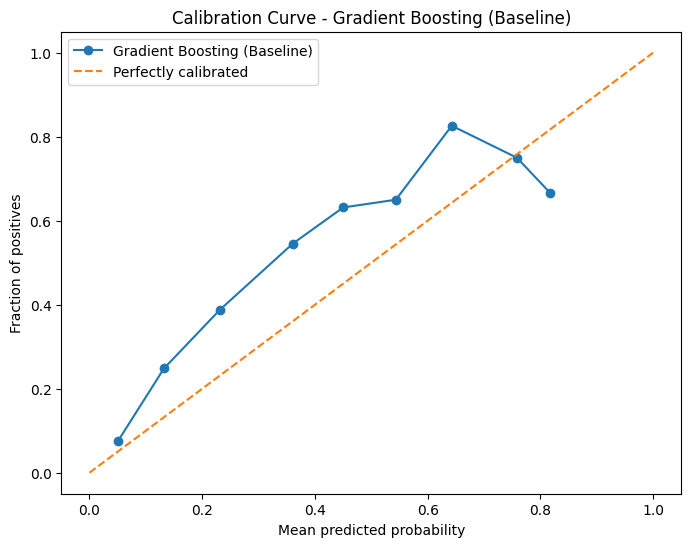

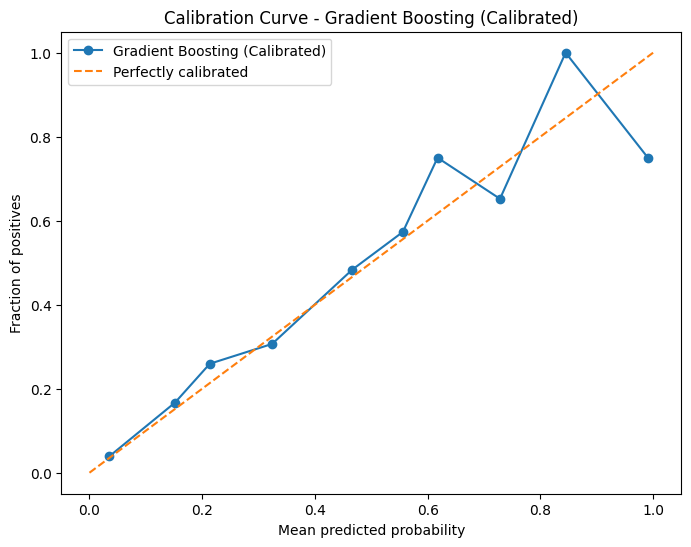

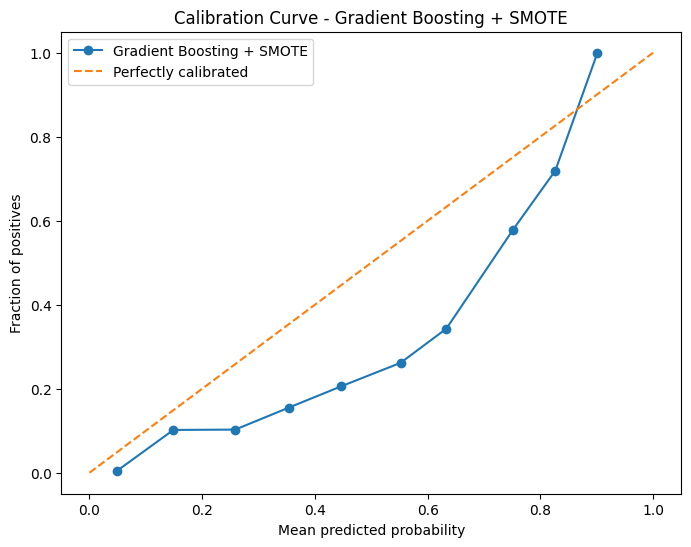

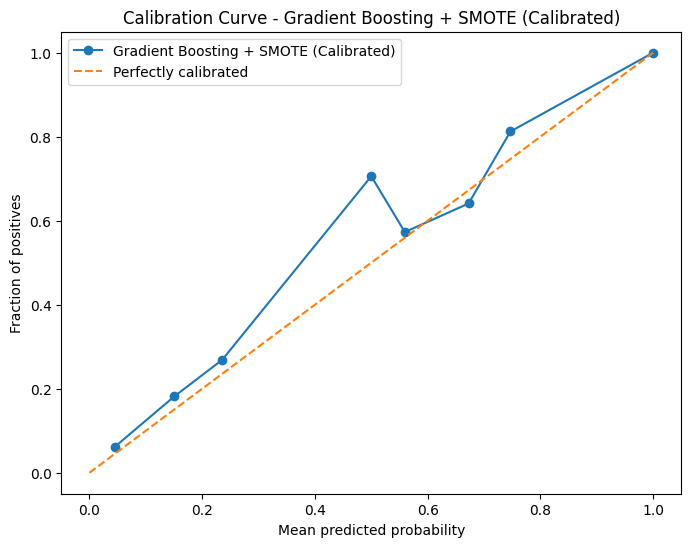

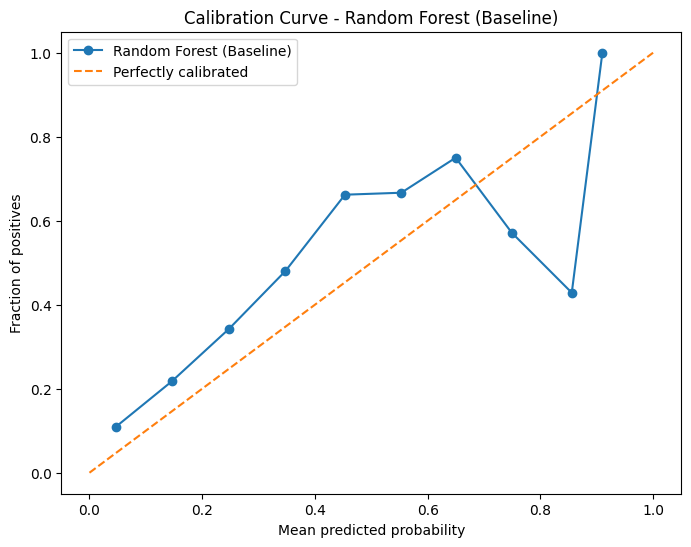

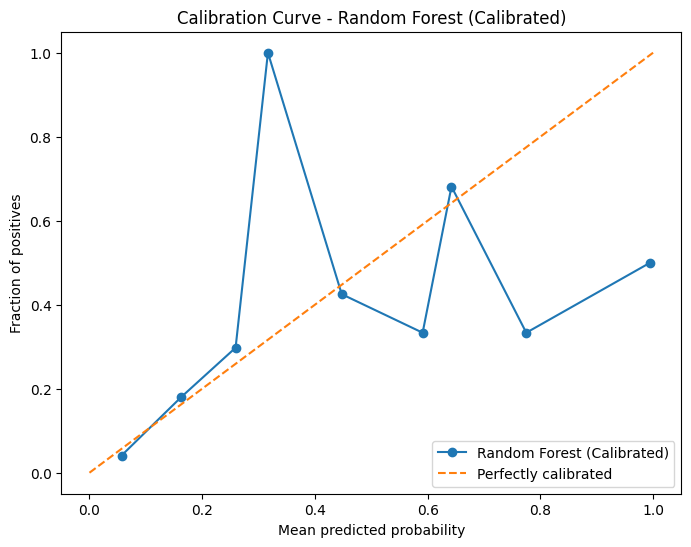

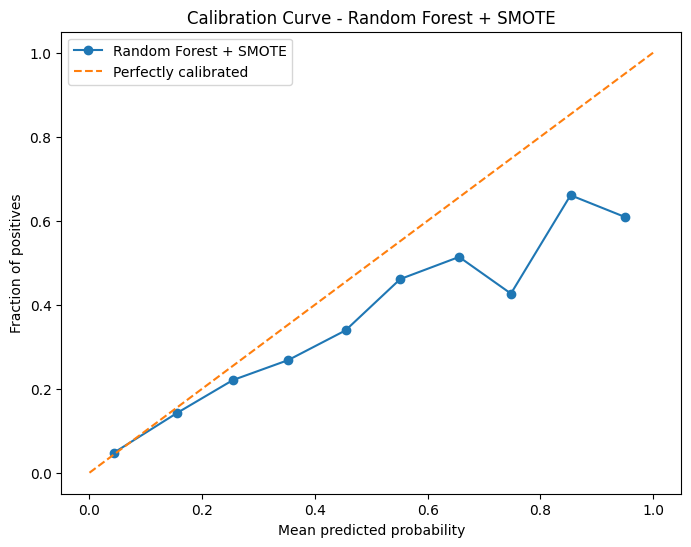

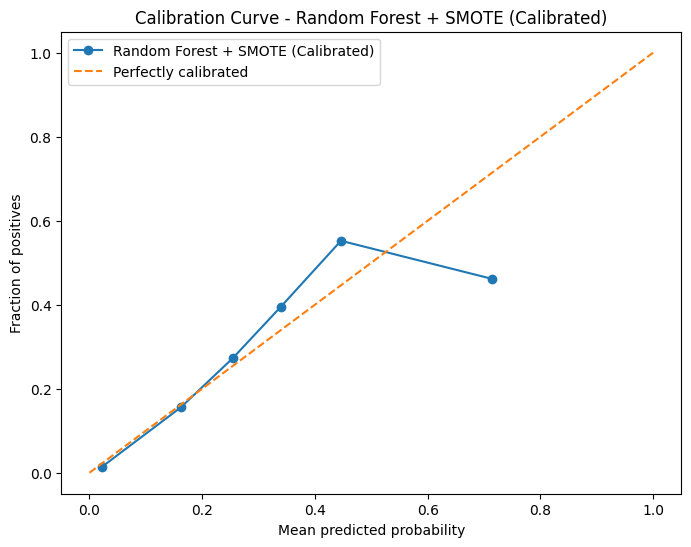

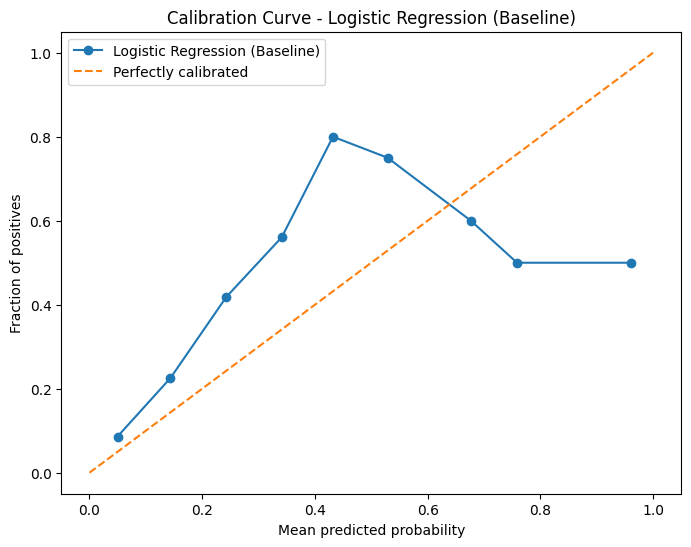

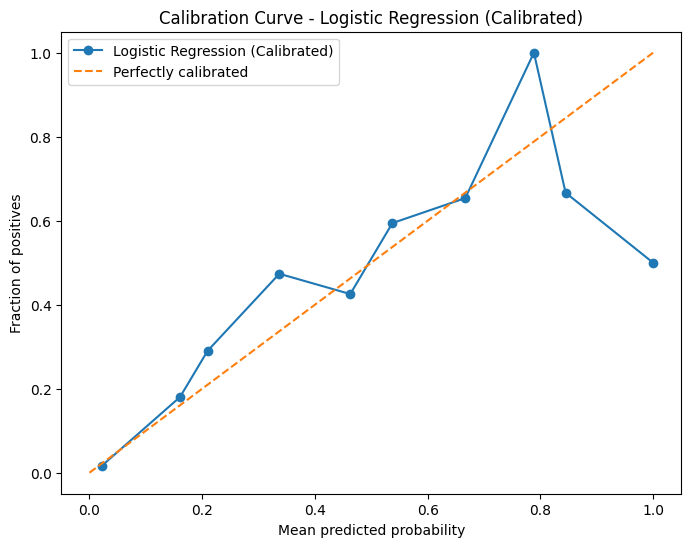

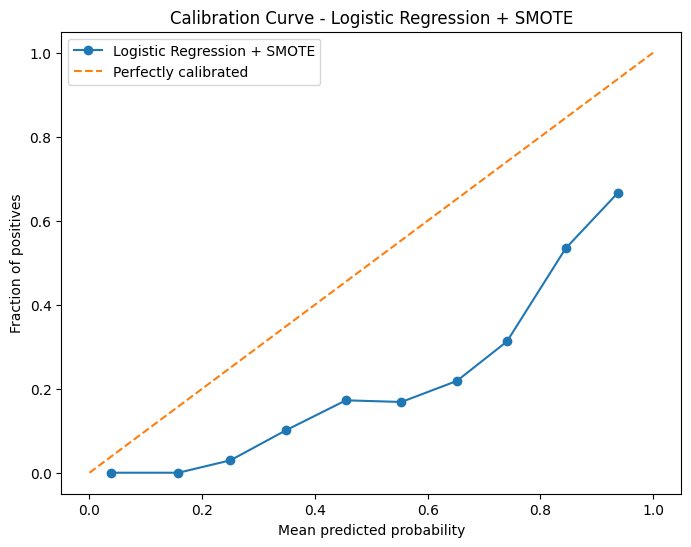

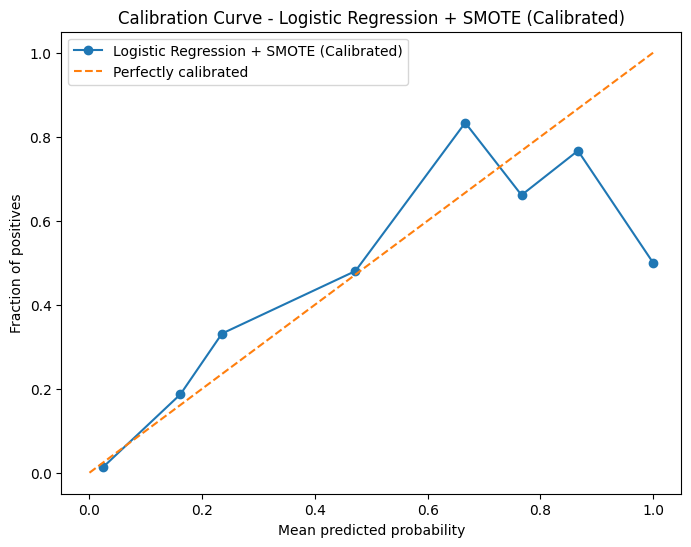

In [42]:
for model in models:
    plot_calibration_curve(model, calibration_data_test)

In [43]:
# Best threshold for each model
def calculate_best_threshold(model, data):
    y_prob = model['model'].predict_proba(data.drop('target', axis=1))[:, 1]

    precision, recall, thresholds = precision_recall_curve(data['target'], y_prob)
    
    pr_auc = average_precision_score(data['target'], y_prob)
    auc = roc_auc_score(data['target'], y_prob)

    f1 = 2 * (precision * recall) / (precision + recall + 1e-10)

    best_idx = np.argmax(f1)
    best_threshold = thresholds[best_idx]

    model['threshold'] = round(best_threshold, 2)
    model['precision'] = round(precision[best_idx], 2)
    model['recall'] = round(recall[best_idx], 2)
    model['f1-score'] = round(f1[best_idx], 2)
    model['auroc'] = round(auc, 2)
    model['pr_auc'] = round(pr_auc, 2)
    
    accuracy = accuracy_score(data['target'], y_prob >= model['threshold'])
    model['accuracy'] = round(accuracy, 2)

    brier_score = brier_score_loss(data['target'], y_prob)
    model['brier_score'] = round(brier_score, 2)

In [44]:
for model in models:
    calculate_best_threshold(model, calibration_data_test)

data = pd.DataFrame(models)
data = data[['name', 'threshold', 'accuracy', 'precision', 'recall', 'f1-score', 'auroc', 'pr_auc', 'brier_score']]

In [45]:
data

,name,threshold,accuracy,precision,recall,f1-score,auroc,pr_auc,brier_score
0,Gradient Boosting (Baseline),0.13,0.73,0.42,0.63,0.51,0.78,0.50,0.15
1,Gradient Boosting (Calibrated),0.18,0.63,0.35,0.78,0.48,0.77,0.45,0.14
2,Gradient Boosting + SMOTE,0.51,0.68,0.37,0.68,0.48,0.76,0.48,0.19
3,Gradient Boosting + SMOTE (Calibrated),0.23,0.64,0.34,0.74,0.47,0.75,0.44,0.14
4,Random Forest (Baseline),0.20,0.76,0.46,0.48,0.47,0.74,0.45,0.15
5,Random Forest (Calibrated),0.20,0.76,0.46,0.48,0.47,0.73,0.43,0.15
6,Random Forest + SMOTE,0.25,0.64,0.35,0.75,0.48,0.75,0.43,0.15
7,Random Forest + SMOTE (Calibrated),0.25,0.69,0.38,0.64,0.48,0.74,0.40,0.15
8,Logistic Regression (Baseline),0.14,0.67,0.37,0.66,0.47,0.75,0.45,0.16
9,Logistic Regression (Calibrated),0.20,0.71,0.39,0.59,0.47,0.74,0.42,0.15


In [46]:
models = [{'model': gboost_model, 'name': 'Gradient Boosting (Baseline)', 'threshold':0.10},
          {'model': gboost_calibrated_model, 'name': 'Gradient Boosting (Calibrated)', 'threshold':0.09},
          {'model': gboost_pipeline, 'name': 'Gradient Boosting + SMOTE', 'threshold':0.42},
          {'model': gboost_calibrated_model_sm, 'name': 'Gradient Boosting + SMOTE (Calibrated)', 'threshold':0.15},
          {'model': rf_model, 'name': 'Random Forest (Baseline)', 'threshold':0.11},
          {'model': rf_calibrated_model, 'name': 'Random Forest (Calibrated)','threshold':0.11},
          {'model': rf_model_pipeline, 'name': 'Random Forest + SMOTE','threshold':0.23},
          {'model': rf_calibrated_model_sm, 'name': 'Random Forest + SMOTE (Calibrated)', 'threshold':0.12},
          {'model': lr_model, 'name': 'Logistic Regression (Baseline)','threshold':0.13},
          {'model': lr_calibrated_model, 'name': 'Logistic Regression (Calibrated)','threshold':0.17},
          {'model': lr_model_pipeline, 'name': 'Logistic Regression + SMOTE','threshold':0.60},
          {'model': lr_calibrated_model_sm, 'name': 'Logistic Regression + SMOTE (Calibrated)','threshold':0.18}]

In [47]:
results = []

for model in models:
    
    y_prob = model['model'].predict_proba(calibration_data_test.drop('target', axis=1))[:, 1]

    threshold = model['threshold']
   
    y_pred = (y_prob >= threshold).astype(int)

    report = classification_report(
        calibration_data_test['target'],
        y_pred,
        labels=[0, 1],
        target_names=['Active', 'IIT'],
        output_dict=True,
        zero_division=0
    )

    for class_name in ['IIT']:
        results.append({
            'Model': model['name'],
            'Outcome': class_name,
            'Threshold': threshold,
            'Accuracy': report['accuracy'],
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-score': report[class_name]['f1-score'],
            'Brier Score': brier_score_loss(calibration_data_test['target'], y_prob),
            'AUROC': roc_auc_score(calibration_data_test['target'], y_prob),
            'PR-AUC': average_precision_score(calibration_data_test['target'], y_prob)
        })

    data = pd.DataFrame(results).round(2)

data

,Model,Outcome,Threshold,Accuracy,Precision,Recall,F1-score,Brier Score,AUROC,PR-AUC
0,Gradient Boosting (Baseline),IIT,0.10,0.60,0.33,0.85,0.48,0.15,0.78,0.50
1,Gradient Boosting (Calibrated),IIT,0.09,0.49,0.29,0.95,0.45,0.14,0.77,0.45
2,Gradient Boosting + SMOTE,IIT,0.42,0.60,0.33,0.80,0.47,0.19,0.76,0.48
3,Gradient Boosting + SMOTE (Calibrated),IIT,0.15,0.56,0.31,0.85,0.46,0.14,0.75,0.44
4,Random Forest (Baseline),IIT,0.11,0.62,0.33,0.74,0.46,0.15,0.74,0.45
5,Random Forest (Calibrated),IIT,0.11,0.47,0.28,0.91,0.43,0.15,0.73,0.43
6,Random Forest + SMOTE,IIT,0.23,0.62,0.34,0.78,0.47,0.15,0.75,0.43
7,Random Forest + SMOTE (Calibrated),IIT,0.12,0.36,0.25,0.99,0.40,0.15,0.74,0.40
8,Logistic Regression (Baseline),IIT,0.13,0.64,0.34,0.71,0.46,0.16,0.75,0.45
9,Logistic Regression (Calibrated),IIT,0.17,0.61,0.33,0.73,0.45,0.15,0.74,0.42


In [48]:
calibration_data_fit['target'].value_counts()

target
0    1157
1     333
Name: count, dtype: int64

In [49]:
# Analyzing the best operational threshold for each model
def analyze_best_threshold(model, data):
    y_prob = model['model'].predict_proba(data.drop('target', axis=1))[:, 1]

    results = []

    for threshold in [round(x * 0.01, 2) for x in range(101)]:
        y_pred = (y_prob >= threshold).astype(int)

        report = classification_report(
            data['target'],
            y_pred,
            labels=[0, 1],
            target_names=['Active', 'IIT'],
            output_dict=True,
            zero_division=0
        )

        for class_name in ['Active', 'IIT']:
            results.append({
                'Model': model['name'],
                'Outcome': class_name,
                'Threshold': threshold,
                'Accuracy': report['accuracy'],
                'Precision': report[class_name]['precision'],
                'Recall': report[class_name]['recall'],
                'F1-score': report[class_name]['f1-score'],
                'Brier Score': brier_score_loss(data['target'], y_prob),
                'AUROC': roc_auc_score(data['target'], y_prob),
                'PR-AUC': average_precision_score(data['target'], y_prob)
            })

    return pd.DataFrame(results).round(2)
    

In [50]:
# Visualizing the best operational threshold for each model
thresholds = pd.DataFrame([])
for model in models:
    results = analyze_best_threshold(model, calibration_data_test)
    thresholds = pd.concat([thresholds, results], ignore_index=True)

thresholds

,Model,Outcome,Threshold,Accuracy,Precision,Recall,F1-score,Brier Score,AUROC,PR-AUC
0,Gradient Boosting (Baseline),Active,0.00,0.22,0.00,0.00,0.00,0.15,0.78,0.50
1,Gradient Boosting (Baseline),IIT,0.00,0.22,0.22,1.00,0.36,0.15,0.78,0.50
2,Gradient Boosting (Baseline),Active,0.01,0.34,1.00,0.15,0.27,0.15,0.78,0.50
3,Gradient Boosting (Baseline),IIT,0.01,0.34,0.25,1.00,0.40,0.15,0.78,0.50
4,Gradient Boosting (Baseline),Active,0.02,0.39,1.00,0.22,0.36,0.15,0.78,0.50
...,...,...,...,...,...,...,...,...,...,...
2419,Logistic Regression + SMOTE (Calibrated),IIT,0.98,0.78,0.50,0.00,0.00,0.15,0.75,0.44
2420,Logistic Regression + SMOTE (Calibrated),Active,0.99,0.78,0.78,1.00,0.88,0.15,0.75,0.44
2421,Logistic Regression + SMOTE (Calibrated),IIT,0.99,0.78,0.50,0.00,0.00,0.15,0.75,0.44
2422,Logistic Regression + SMOTE (Calibrated),Active,1.00,0.78,0.78,1.00,0.88,0.15,0.75,0.44


In [51]:
thresholds.to_excel('best_operational_thresholds.xlsx', index=False)

In [52]:
# Generate classification report
def generate_classification_report(model, data):
    predictions = (model['model'].predict_proba(data.drop('target', axis=1))[:, 1] >= model['threshold']).astype(int)

    report = classification_report(
        data['target'], predictions,  labels=[0, 1],output_dict=True, zero_division=0
    )

    df_report = pd.DataFrame(report).T

    # Plot precision, recall and F1-score
    sns.heatmap(
        df_report.loc[['0', '1',], ['precision', 'recall', 'f1-score']],
        annot=True,
        cmap='Reds',
        fmt='.2f',
        vmin=0,
        vmax=1
    )

    plt.title(f"{model['name']} - Classification Report")
    plt.xlabel('Metric')
    plt.ylabel('Class (0 = Active, 1 = IIT)')
    plt.tight_layout()
    plt.show()

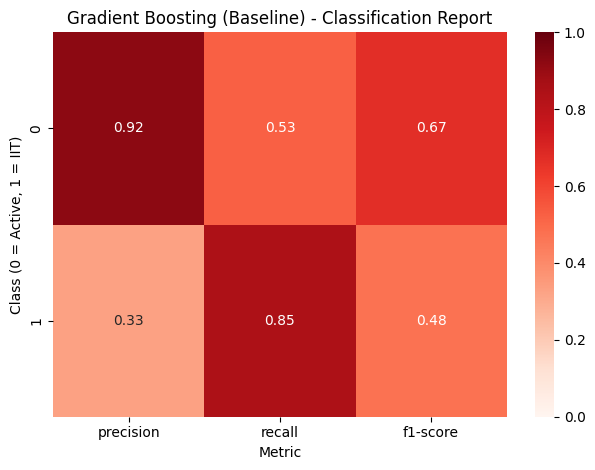

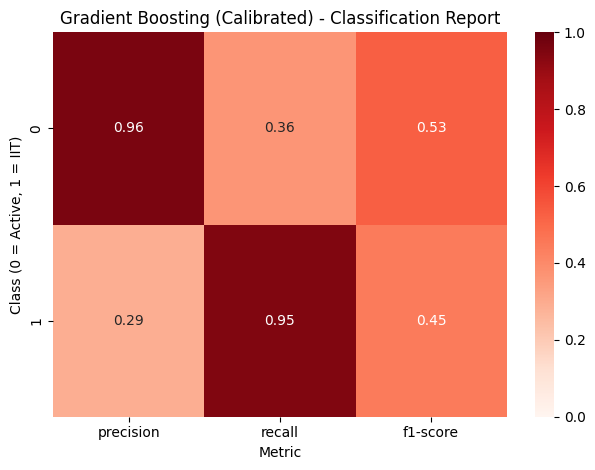

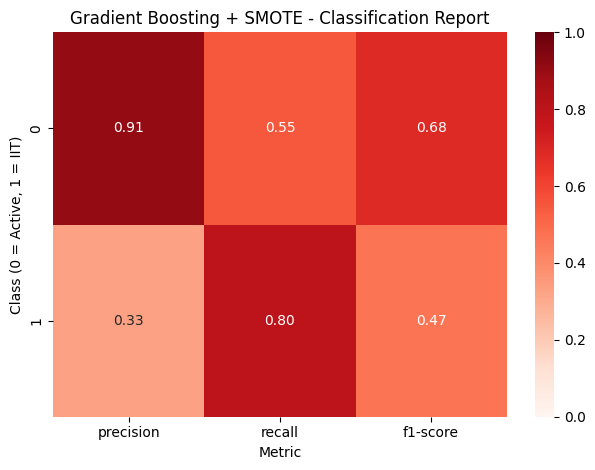

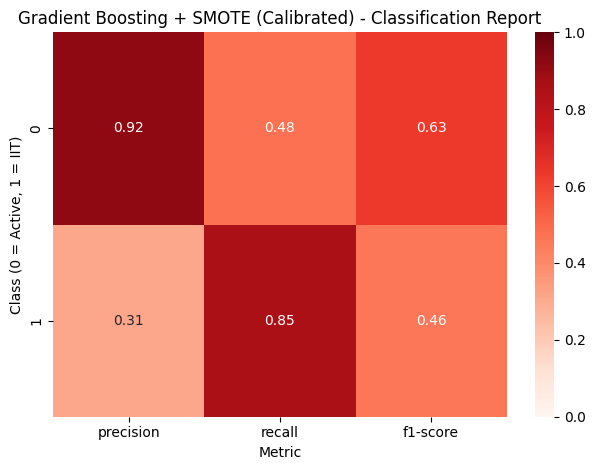

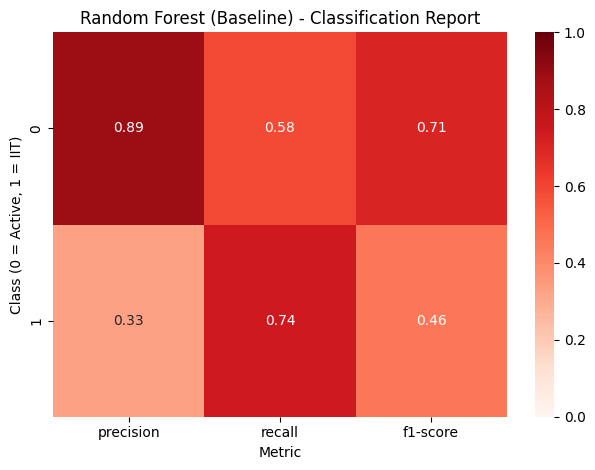

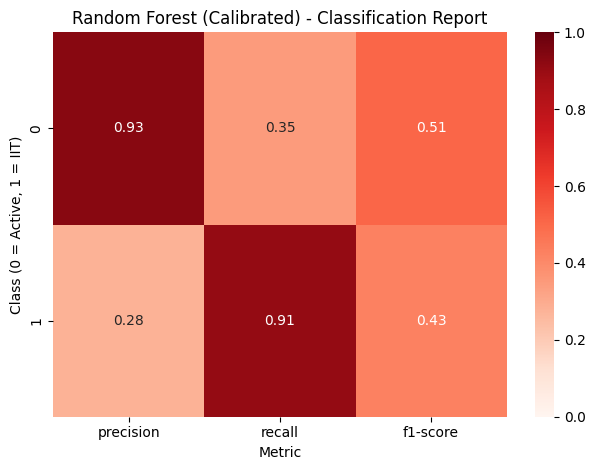

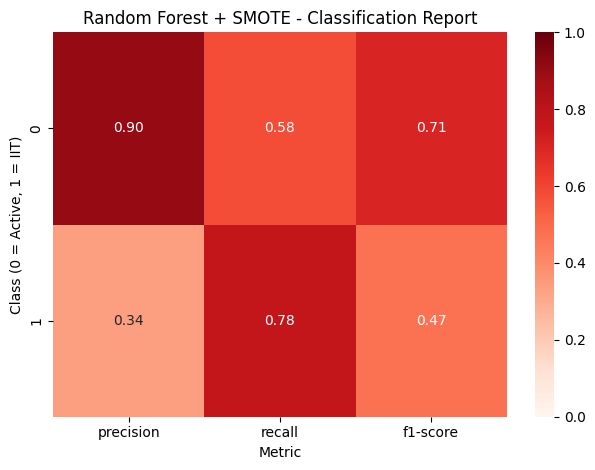

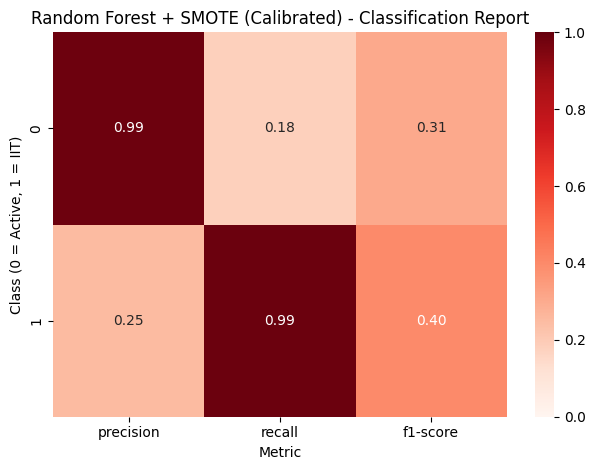

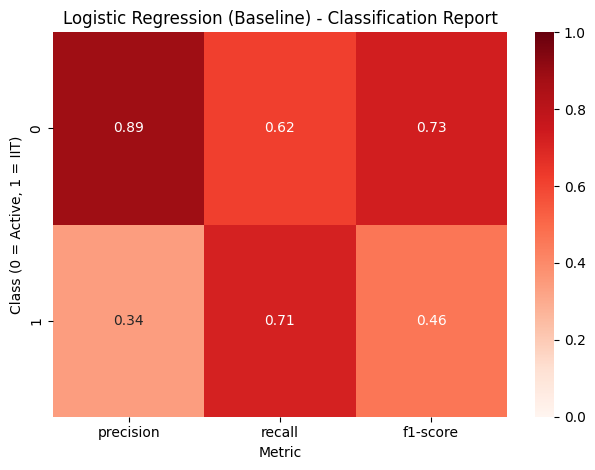

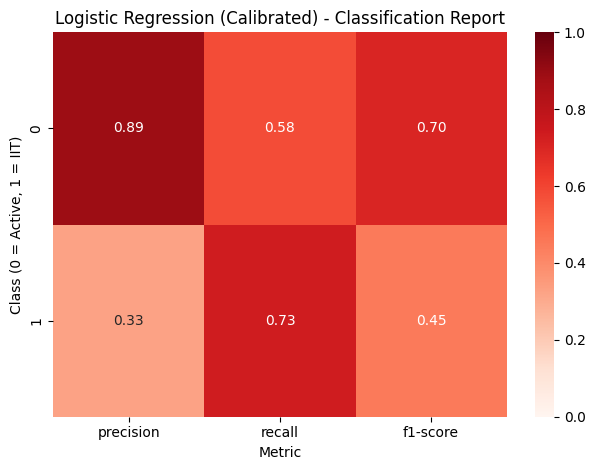

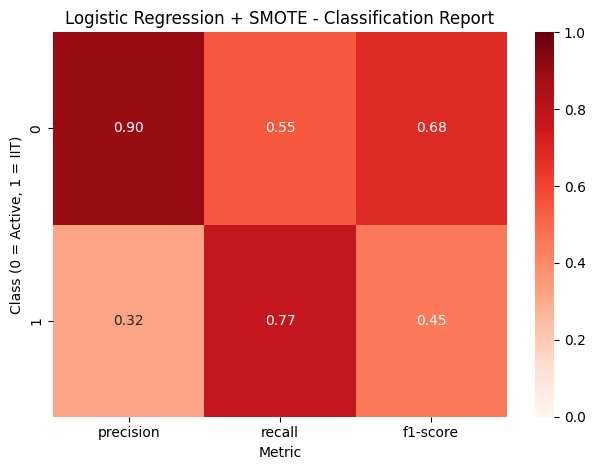

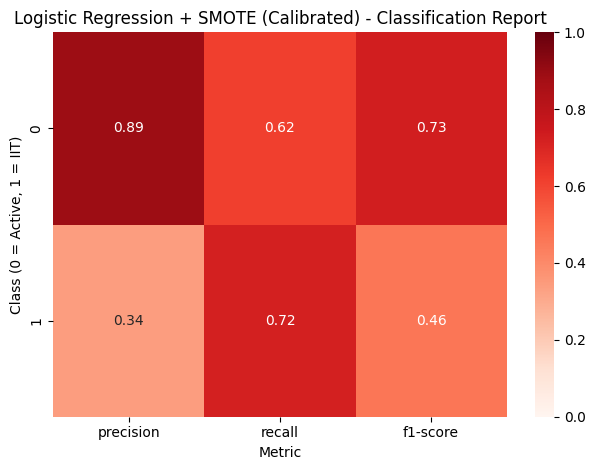

In [53]:
for model in models:
    generate_classification_report(model, calibration_data_test)

In [54]:
# Plot confusion matrix
def plot_confusion_matrix(model, data):
    predictions = (model['model'].predict_proba(data.drop('target', axis=1))[:, 1] >= model['threshold']).astype(int)
    confusion_mat = confusion_matrix(data['target'], predictions)

    plt.imshow(confusion_mat, cmap='Reds')
    plt.title(f'{model["name"]} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.xticks([0, 1], ['Active on ART', 'IIT/LTFU'])
    plt.yticks([0, 1], ['Active on ART', 'IIT/LTFU'])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, str(confusion_mat[i, j]), ha='center', va='center')
    plt.show()

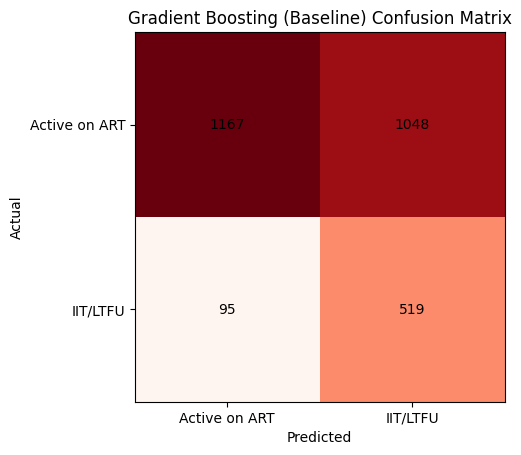

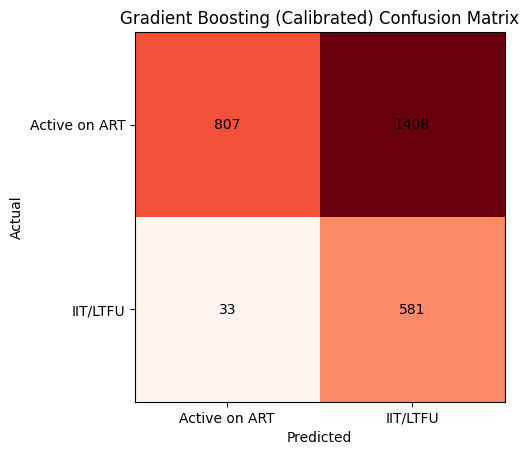

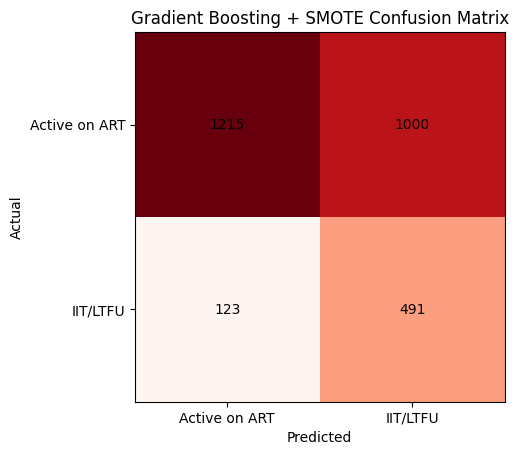

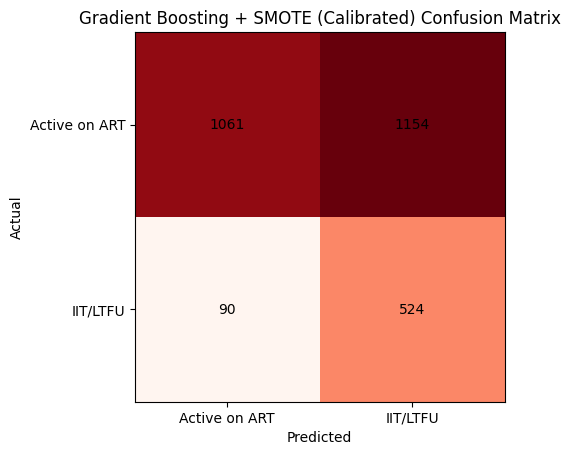

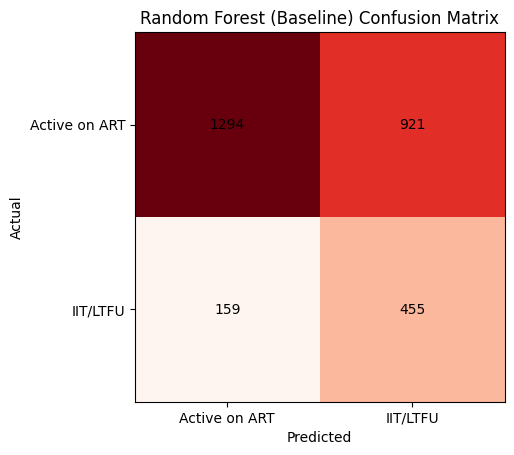

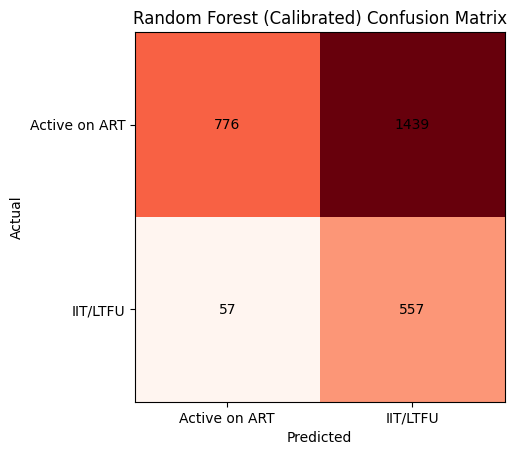

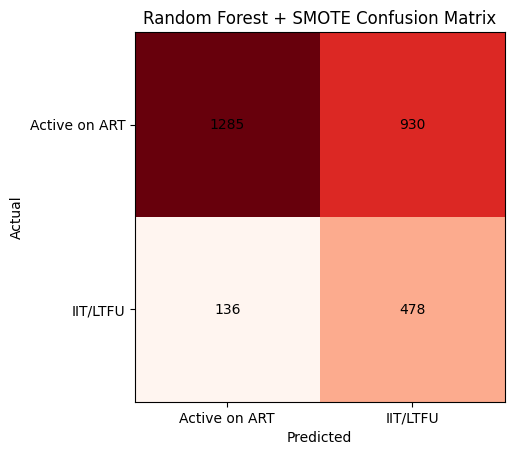

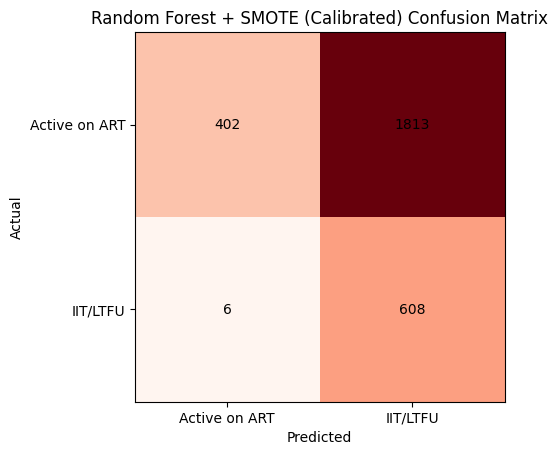

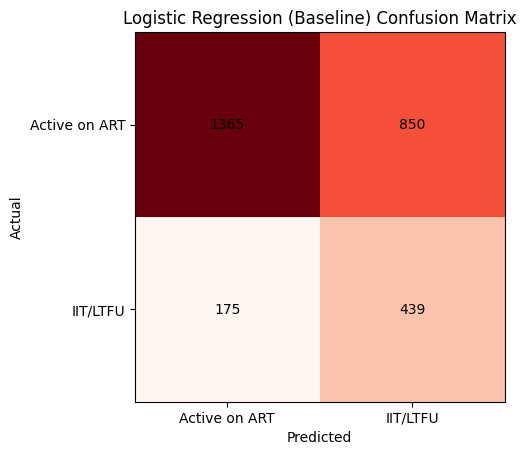

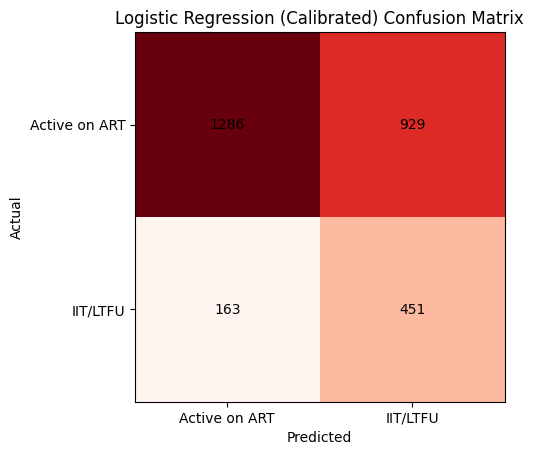

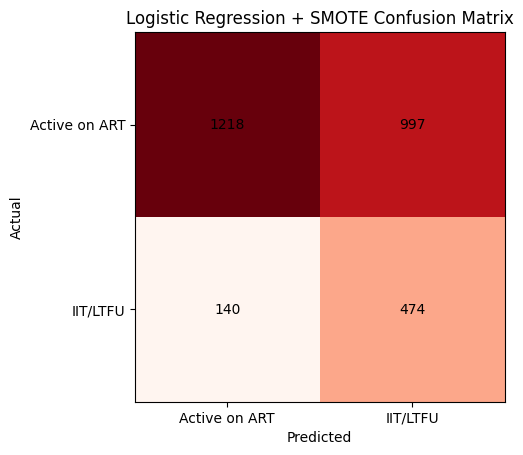

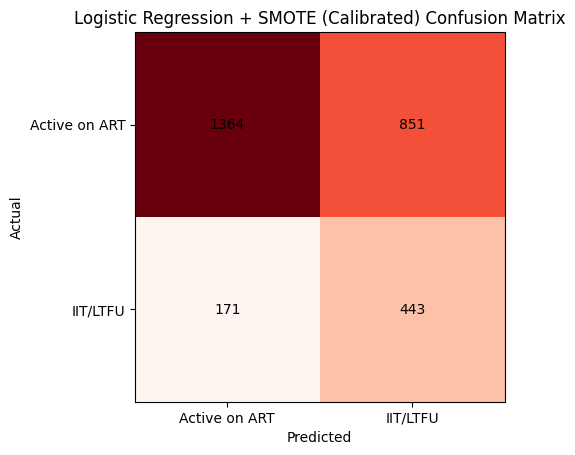

In [55]:
for model in models:
    plot_confusion_matrix(model, calibration_data_test)


In [56]:
# Plot ROC Curve and AUC
def plot_roc_curve(model, data):
    y_prob = model['model'].predict_proba(data.drop('target', axis=1))[:, 1]

    fpr, tpr, thresholds = roc_curve(data['target'], y_prob)
    auc = roc_auc_score(data['target'], y_prob)

    plt.figure(figsize=(8, 6))

    plt.plot(fpr, tpr, label=f'{model["name"]} (AUC = {auc:.2f})')
    plt.plot([0, 1], [0, 1], '--', label=f'Baseline = {data["target"].mean():.2f}')

    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR or Recall)')
    plt.title('ROC Curve')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

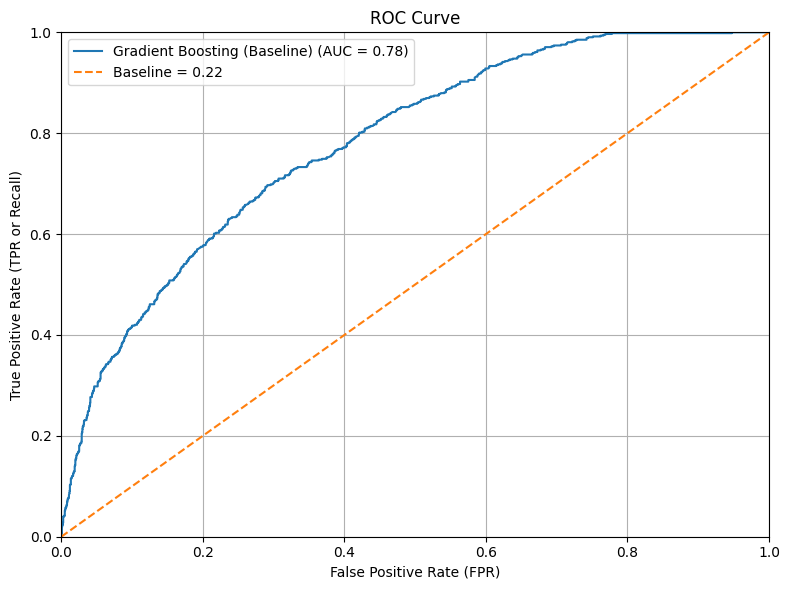

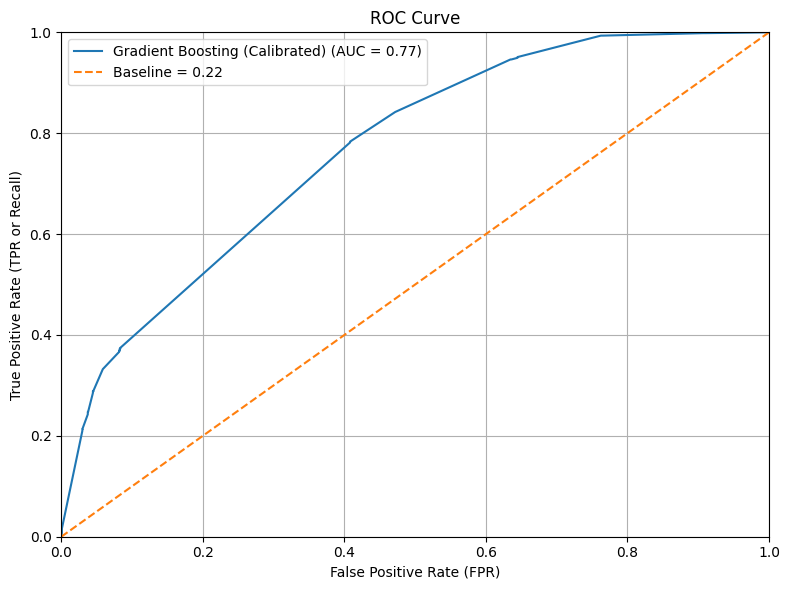

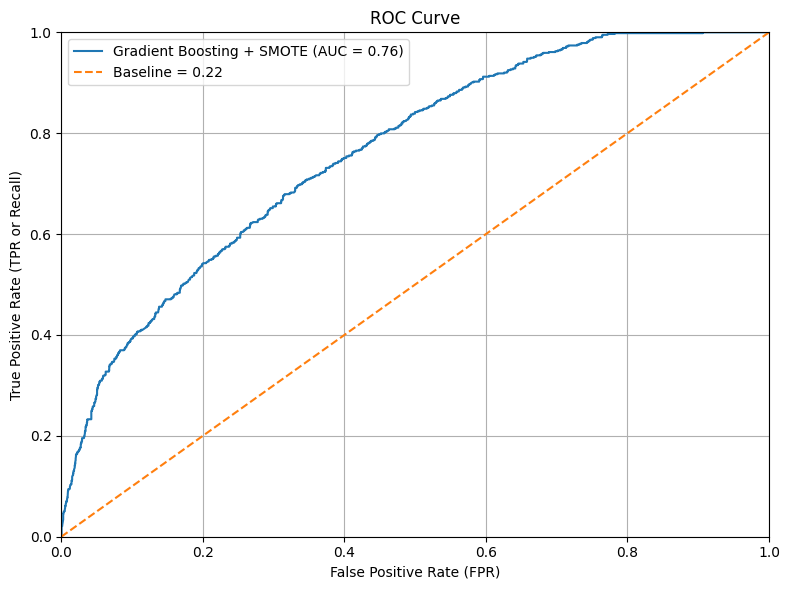

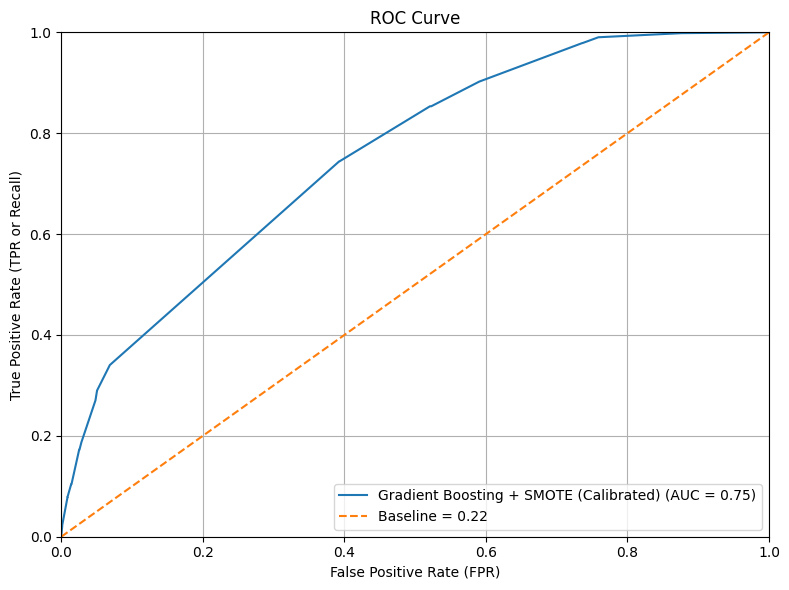

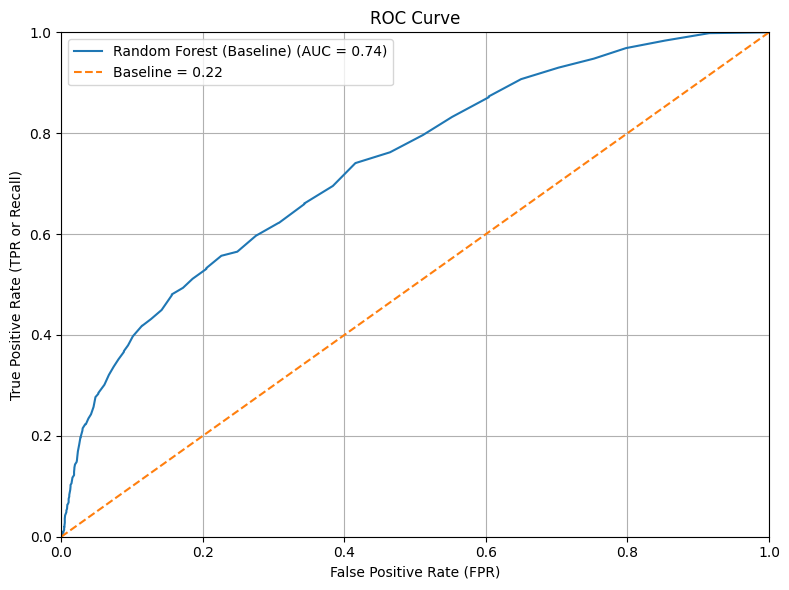

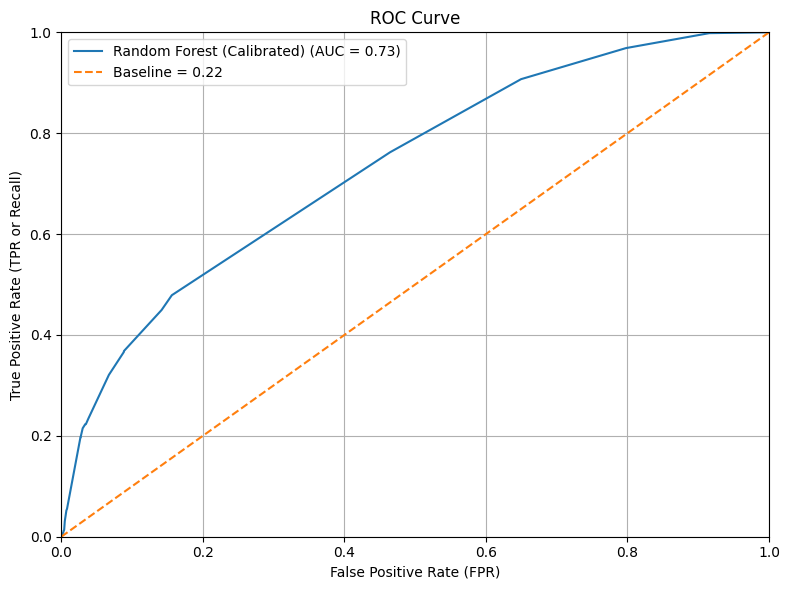

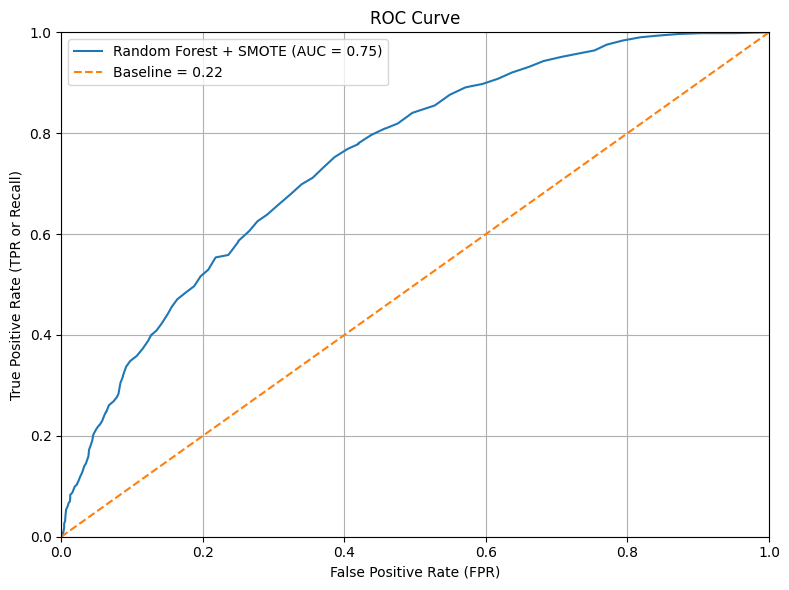

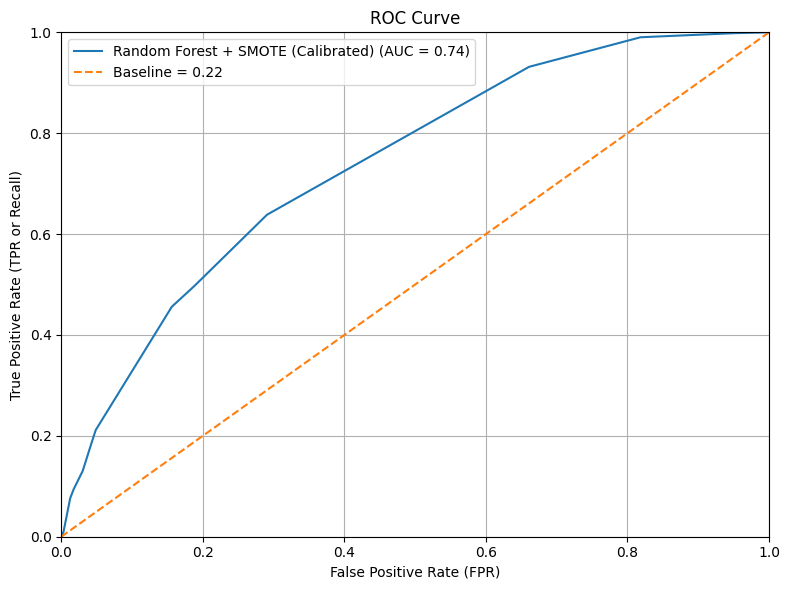

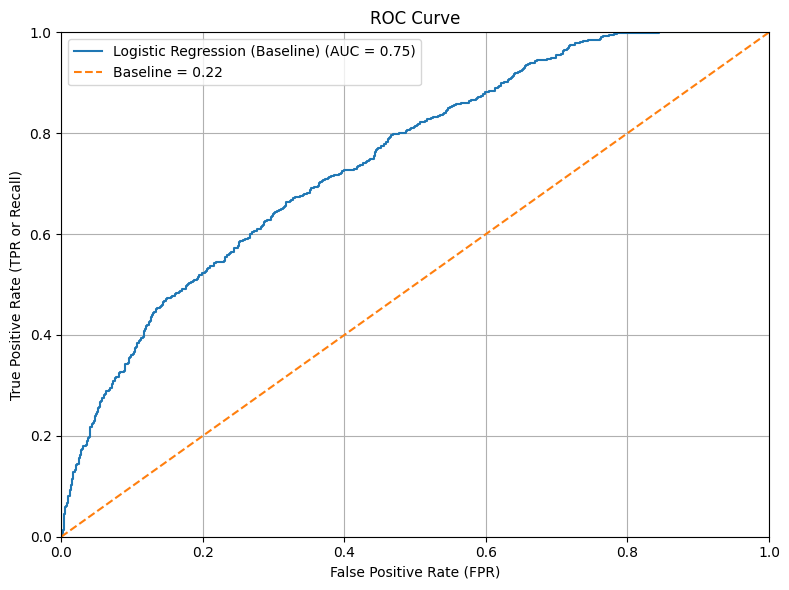

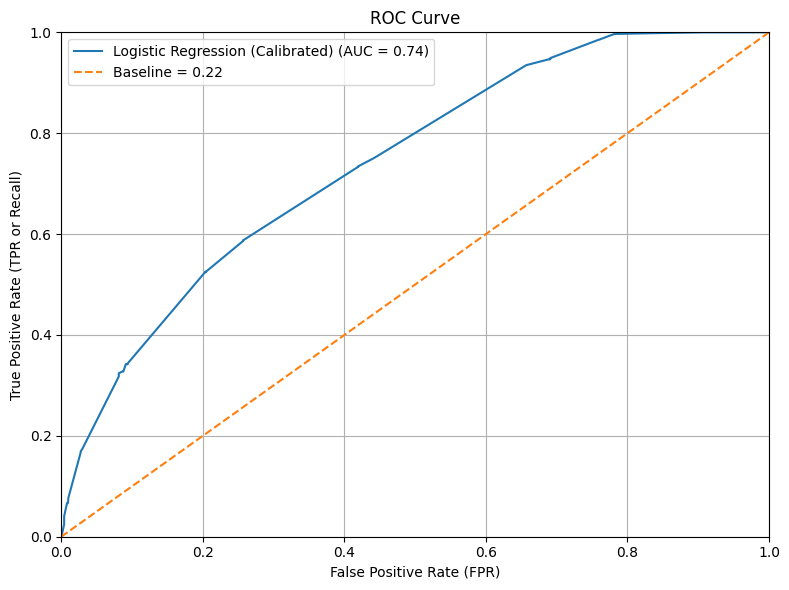

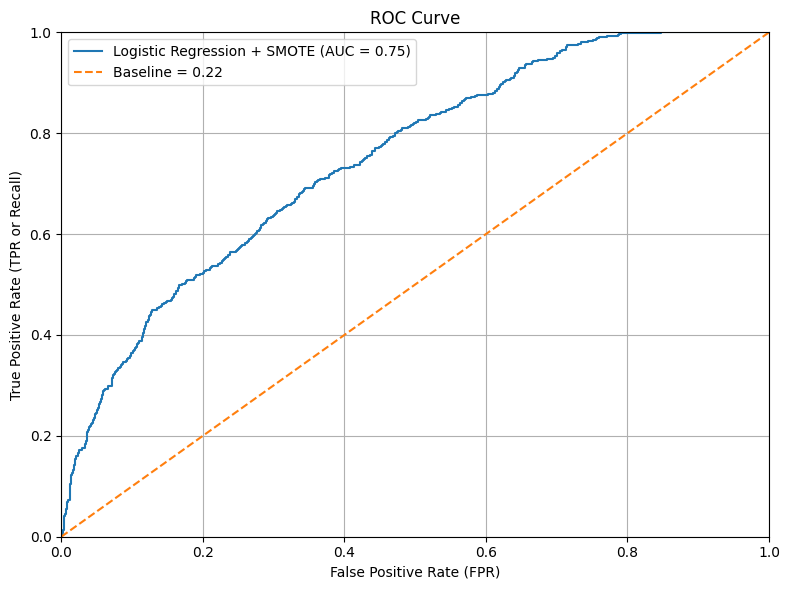

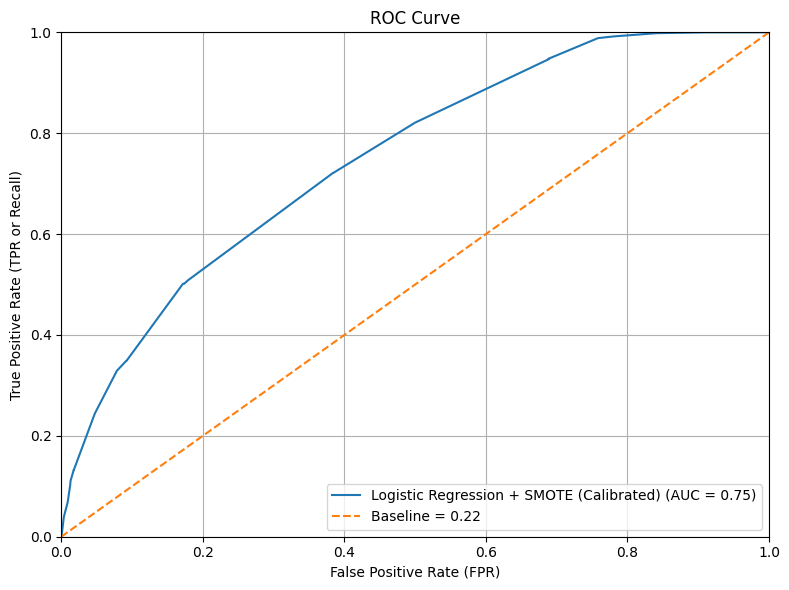

In [57]:
for model in models:
    plot_roc_curve(model, calibration_data_test)

In [58]:
# Plot Precision-Recall Curve
def plot_precision_recall_curve(model, data):
    y_prob = model['model'].predict_proba(data.drop('target', axis=1))[:, 1]

    # Calculate PR-AUC (Average Precision)
    pr_auc = average_precision_score(data['target'], y_prob)

    # Generate Precision-Recall curve
    precision, recall, _ = precision_recall_curve(data['target'], y_prob)

    plt.plot(recall, precision, label=f' {model["name"]} PR-AUC = {pr_auc:.2f}')
    plt.axhline(
        data['target'].mean(),
         color='red',
        linestyle='--',
        label=f'Baseline = {data["target"].mean():.2f}'
    )

    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.title(f'{model["name"]} - Precision-Recall Curve')
    plt.legend()
    plt.grid(True)
    plt.show()

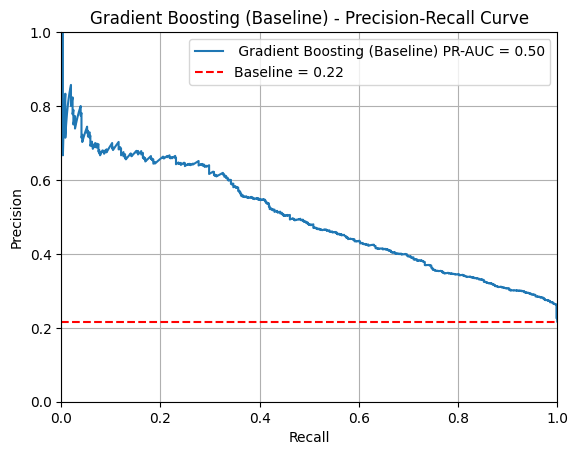

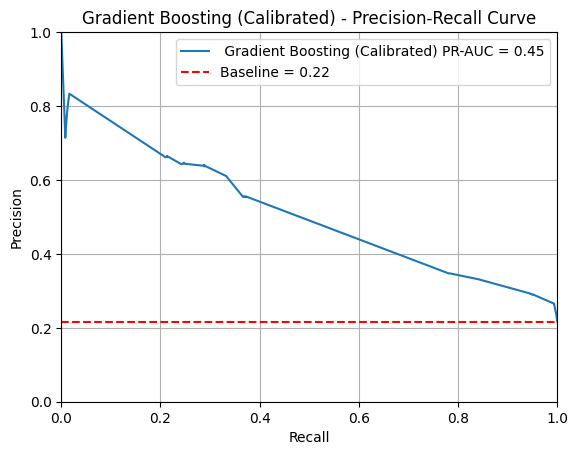

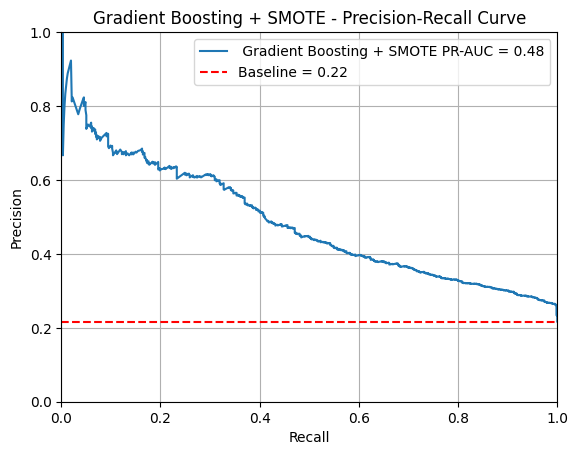

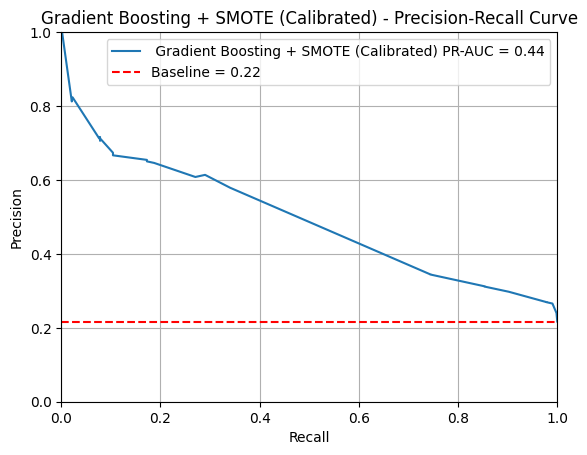

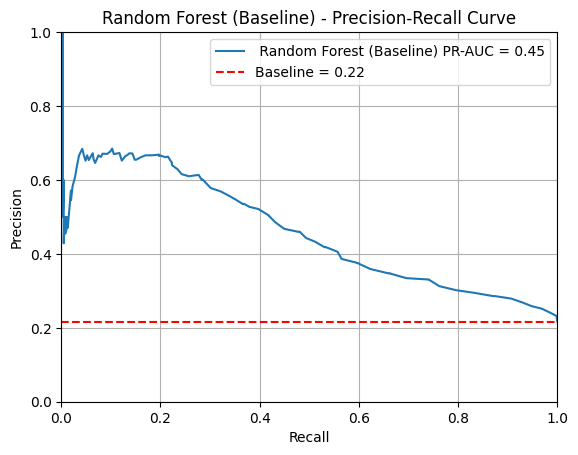

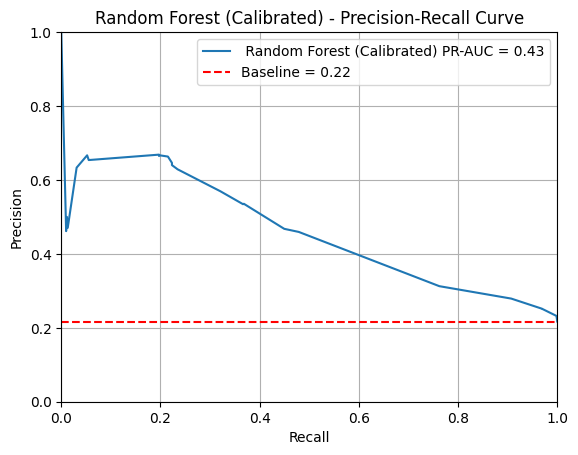

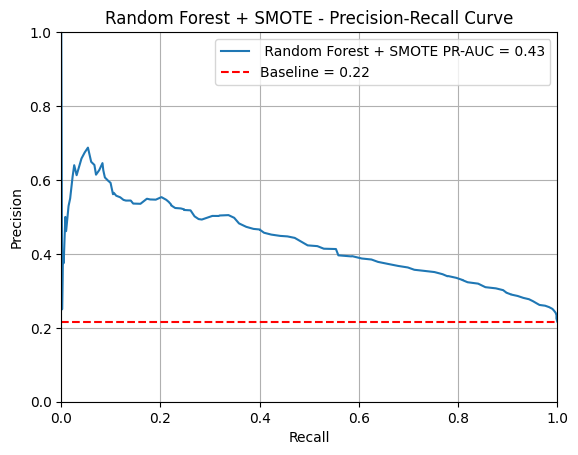

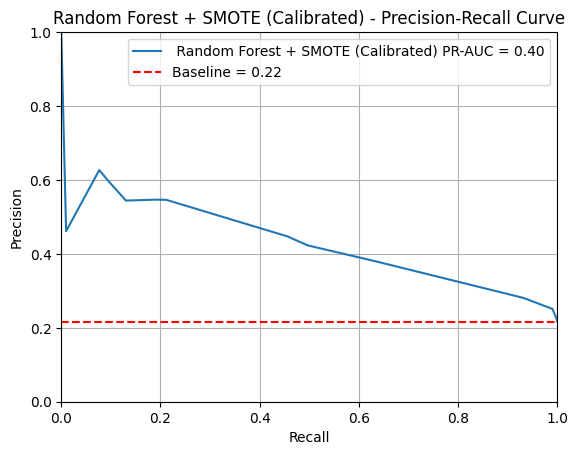

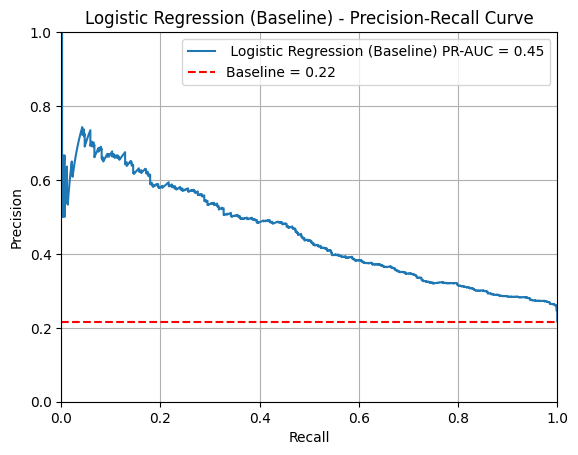

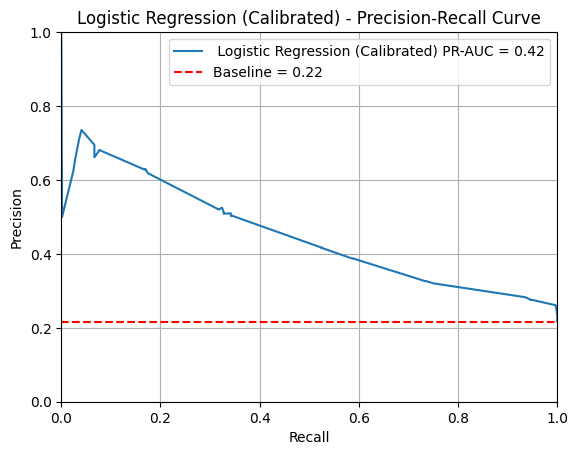

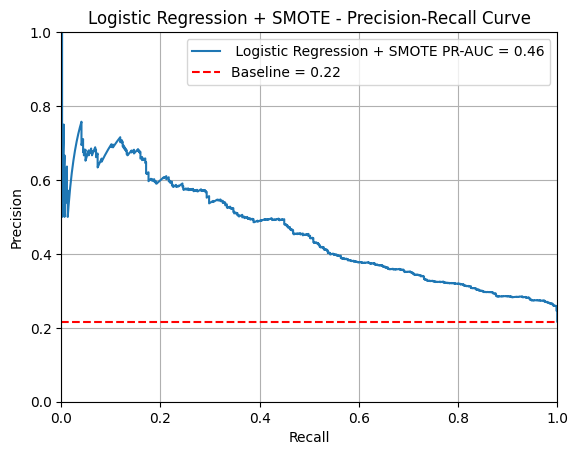

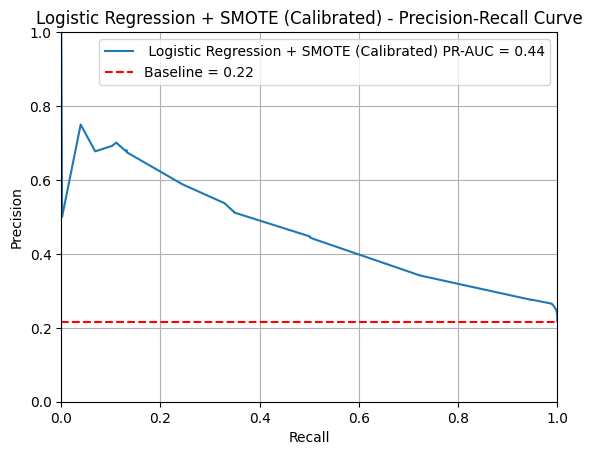

In [59]:
for model in models:
    plot_precision_recall_curve(model, calibration_data_test)

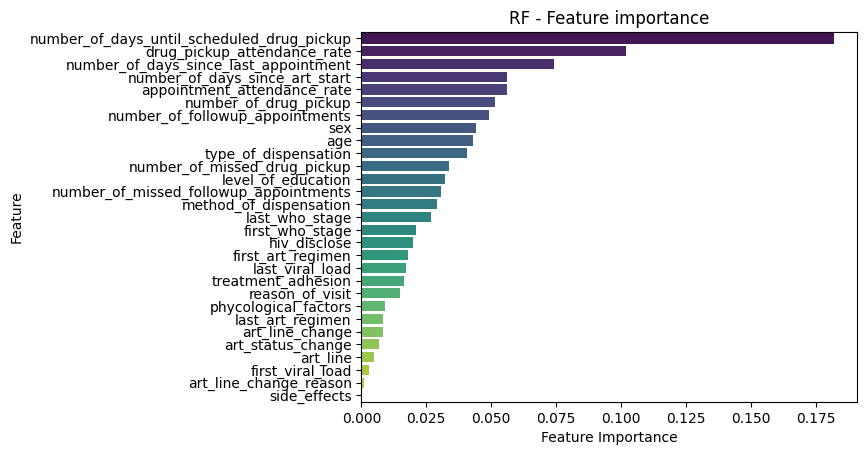

In [60]:
importance = pd.Series(
    rf_model_pipeline.named_steps['model'].feature_importances_,
    index=calibration_data_test.drop('target', axis=1).columns
).sort_values(ascending=False)

sns.barplot(x=importance.values, y=importance.index, palette='viridis', hue=importance.index)
plt.title('RF - Feature importance')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
# plt.tight_layout()
plt.show()

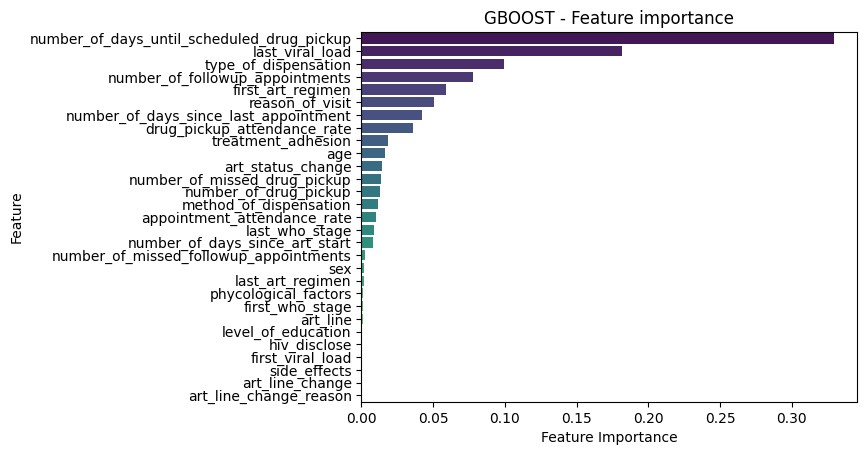

In [61]:
importance = pd.Series(
    gboost_pipeline.named_steps['model'].feature_importances_,
    index=calibration_data_test.drop('target', axis=1).columns
).sort_values(ascending=False)

sns.barplot(x=importance.values, y=importance.index, palette='viridis', hue=importance.index)
plt.title('GBOOST - Feature importance')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
# plt.tight_layout()
plt.show()

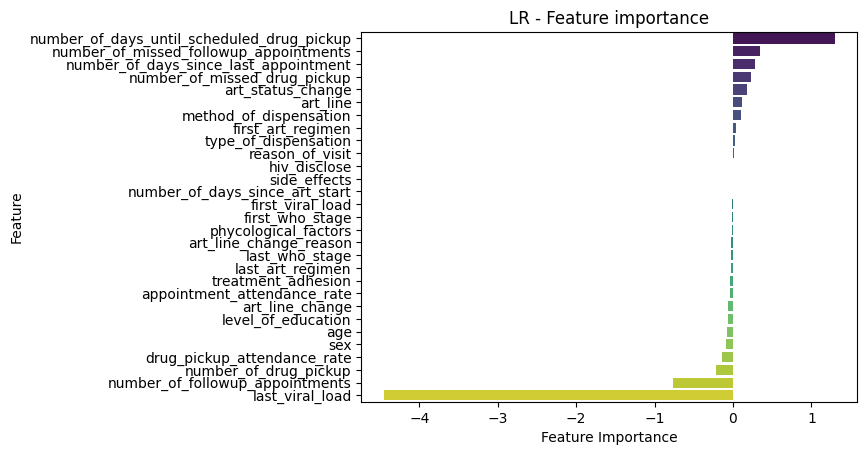

In [62]:
lr = lr_model_pipeline.named_steps["model"]

feature_importance = pd.Series(
    lr.coef_[0],
    index=calibration_data_test.drop('target', axis=1).columns
).sort_values(key=abs, ascending=False)

importance = pd.Series(
    feature_importance,
    index=calibration_data_test.drop('target', axis=1).columns
).sort_values(ascending=False)

sns.barplot(x=importance.values, y=importance.index, palette='viridis', hue=importance.index)
plt.title('LR - Feature importance')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
# plt.tight_layout()
plt.show()

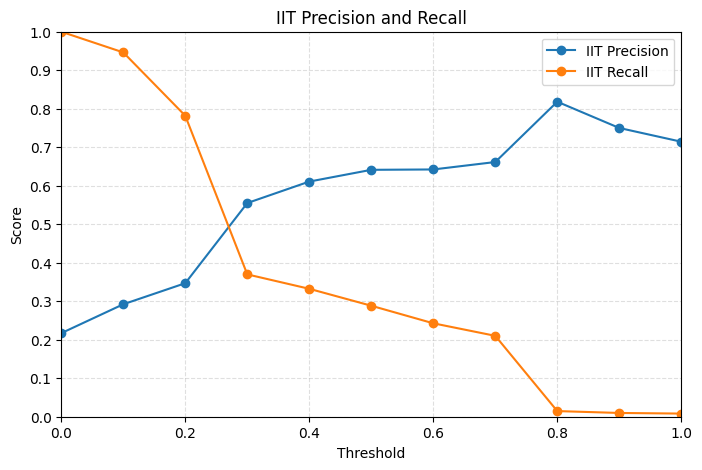

In [63]:
y_prob = gboost_calibrated_model.predict_proba(calibration_data_test.drop('target', axis=1))[:, 1]

thresholds = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.0]

precisions, recalls = [], []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    report = classification_report(
        calibration_data_test['target'], y_pred,
        labels=[0, 1],
        target_names=['Active', 'IIT'],
        zero_division=0,
        output_dict=True
    )

    precisions.append(report['IIT']['precision'])
    recalls.append(report['IIT']['recall'])

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, marker='o', label='IIT Precision')
plt.plot(thresholds, recalls, marker='o', label='IIT Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('IIT Precision and Recall')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.yticks(thresholds)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.show()

In [64]:
_1_maio_testing_data = pd.concat([pd.read_csv('1_MAIO/data_2025Q1.csv')])
_25_setembro_testing_data = pd.concat([pd.read_csv('25_SETEMBRO_DATA/data_2025Q1.csv')])

_1_maio_testing_data['hf_code'] = 200966
_25_setembro_testing_data['hf_code'] = 200291

In [65]:
# # testing_data_ = pd.concat([_25_setembro_testing_data])
# testing_data_ = pd.concat([_1_maio_testing_data])
testing_data_ = pd.concat([_1_maio_testing_data, _25_setembro_testing_data])

In [66]:
testing_data_ = clean_invalid_date(testing_data_)
testing_data_ = testing_data_.loc[testing_data_['age']>= 18]
testing_data_ = testing_data_[~(testing_data_['patient_id'].isin(calibration_data_fit_['patient_id']) & testing_data_['hf_code'].isin(calibration_data_fit_['hf_code']))]
testing_data_ = testing_data_[~(testing_data_['patient_id'].isin(calibration_data_test_['patient_id']) & testing_data_['hf_code'].isin(calibration_data_test_['hf_code']))]
testing_data_ = testing_data_[~(testing_data_['patient_id'].isin(trainning_data_['patient_id']) & testing_data_['hf_code'].isin(trainning_data_['hf_code']))]

testing_data = fill_missing_and_convert_to_int(testing_data_, numeric_columns)
testing_data = convert_date_columns_to_datetime(testing_data, date_columns)
testing_data = convert_sex_column_to_binary(testing_data)
testing_data = compute_days_since_dates(testing_data)
testing_data = separate_predict_features_and_target(testing_data)

In [67]:
testing_data['target'].value_counts()

target
0    254
1    116
Name: count, dtype: int64

In [68]:
selected_models = [
          {'model': gboost_calibrated_model_sm, 'name': 'Gradient Boosting + SMOTE (Calibrated)', 'threshold':0.21},
          {'model': rf_calibrated_model_sm, 'name': 'Random Forest + SMOTE (Calibrated)', 'threshold':0.19},
          {'model': lr_calibrated_model_sm, 'name': 'Logistic Regression + SMOTE (Calibrated)','threshold':0.18}]

In [69]:
# Generate model performance report for the new testing data
model_results = []

for model in models:
    y_prob = model['model'].predict_proba(testing_data.drop('target', axis=1))[:, 1]
    y_pred = (y_prob >= model['threshold']).astype(int)
    pr_auc = average_precision_score(testing_data['target'], y_prob)
    

    report = classification_report(
        testing_data['target'], y_pred,
        labels=[0, 1],
        target_names=['Active', 'IIT'],
        output_dict=True,
        zero_division=0
    )

    model_results.append({
        'Model': model['name'],
        'Threshold': round(model['threshold'], 2),
        'Outcome': 'IIT',
        'Accuracy': round(accuracy_score(testing_data['target'], y_pred), 2),
        'Precision': round(report['IIT']['precision'], 2),
        'Recall': round(report['IIT']['recall'], 2),
        'F1-Score': round(report['IIT']['f1-score'], 2),
        'AUROC': round(roc_auc_score(testing_data['target'], y_prob), 2),
        'PR-AUC': round(pr_auc, 2)
    })
    
    model_results.append({
        'Model': model['name'],
        'Threshold': round(model['threshold'], 2),
        'Outcome': 'Active',
        'Accuracy': round(accuracy_score(testing_data['target'], y_pred), 2),
        'Precision': round(report['Active']['precision'], 2),
        'Recall': round(report['Active']['recall'], 2),
        'F1-Score': round(report['Active']['f1-score'], 2),
        'AUROC': 0,
        'PR-AUC': 0
    })

model_results_data = pd.DataFrame(model_results)

In [70]:
model_results_data

,Model,Threshold,Outcome,Accuracy,Precision,Recall,F1-Score,AUROC,PR-AUC
0,Gradient Boosting (Baseline),0.10,IIT,0.57,0.41,0.91,0.57,0.76,0.61
1,Gradient Boosting (Baseline),0.10,Active,0.57,0.91,0.41,0.57,0.00,0.00
2,Gradient Boosting (Calibrated),0.09,IIT,0.41,0.35,0.99,0.51,0.75,0.55
3,Gradient Boosting (Calibrated),0.09,Active,0.41,0.97,0.15,0.25,0.00,0.00
4,Gradient Boosting + SMOTE,0.42,IIT,0.57,0.41,0.89,0.56,0.76,0.60
5,Gradient Boosting + SMOTE,0.42,Active,0.57,0.89,0.42,0.57,0.00,0.00
6,Gradient Boosting + SMOTE (Calibrated),0.15,IIT,0.49,0.37,0.91,0.53,0.76,0.57
7,Gradient Boosting + SMOTE (Calibrated),0.15,Active,0.49,0.87,0.30,0.44,0.00,0.00
8,Random Forest (Baseline),0.11,IIT,0.49,0.35,0.75,0.48,0.70,0.59
9,Random Forest (Baseline),0.11,Active,0.49,0.77,0.37,0.50,0.00,0.00


In [71]:
testing_data['target'].value_counts(normalize=False)

target
0    254
1    116
Name: count, dtype: int64

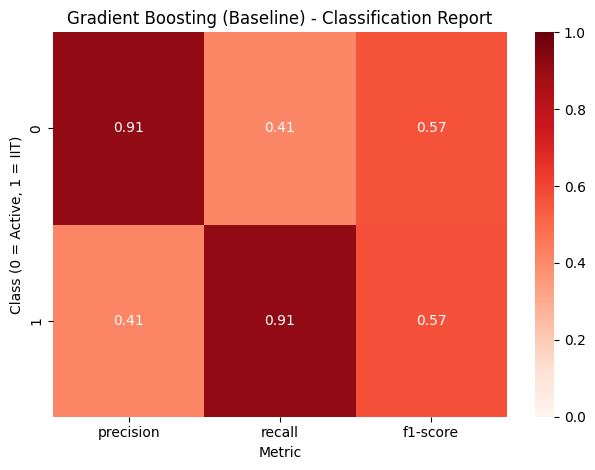

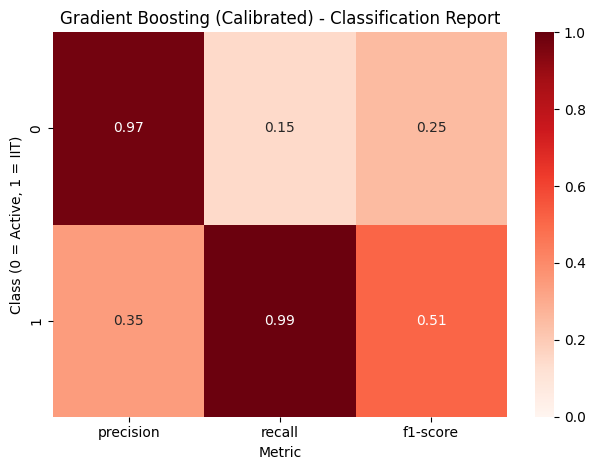

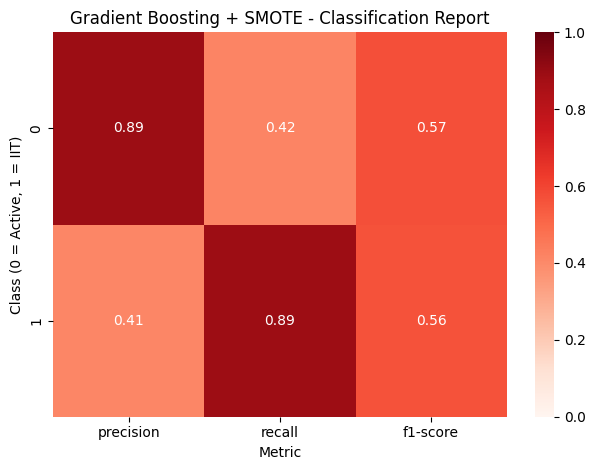

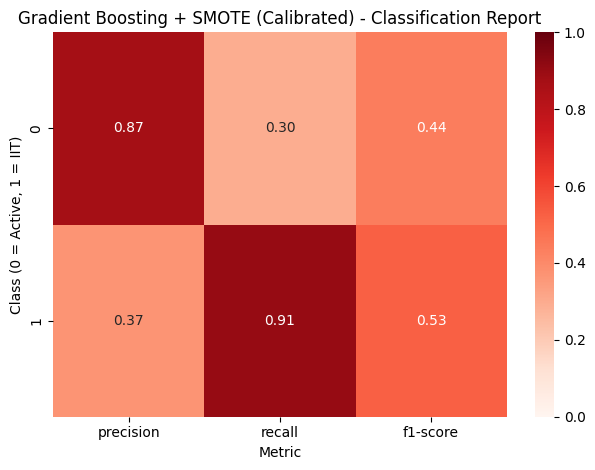

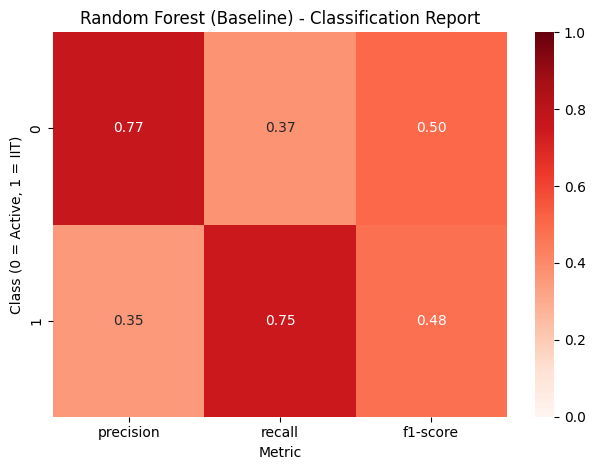

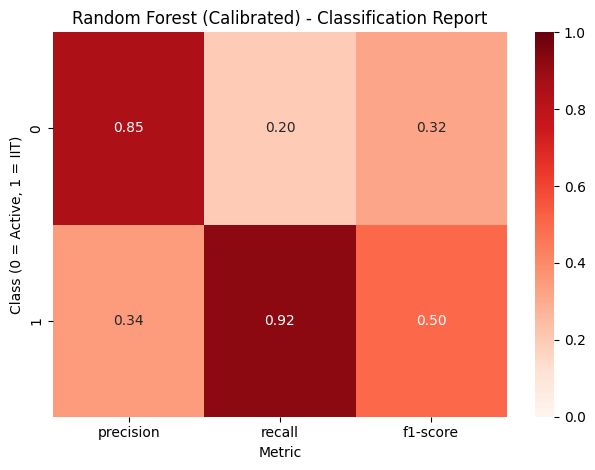

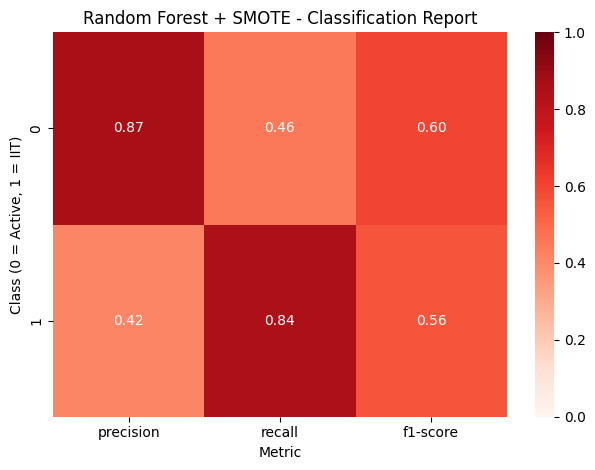

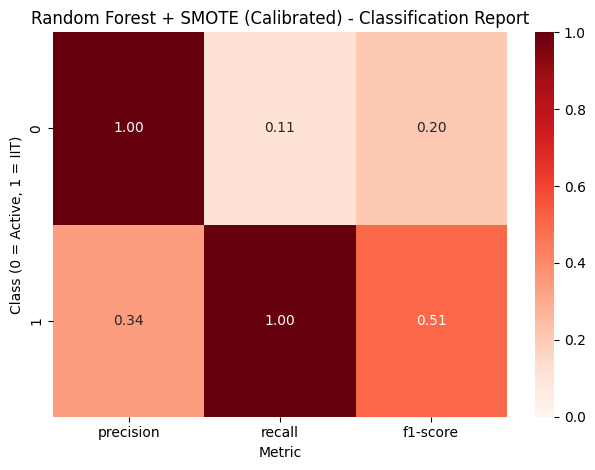

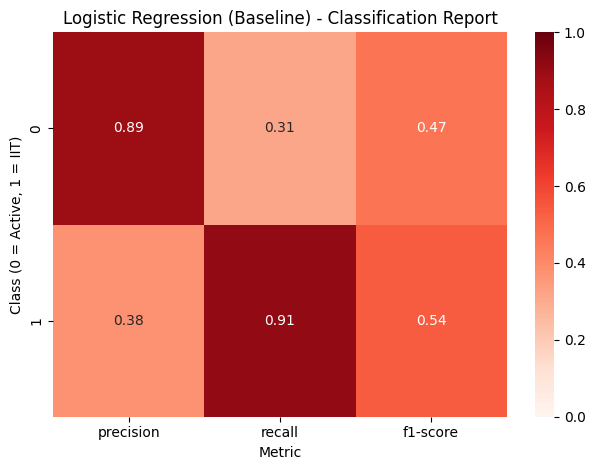

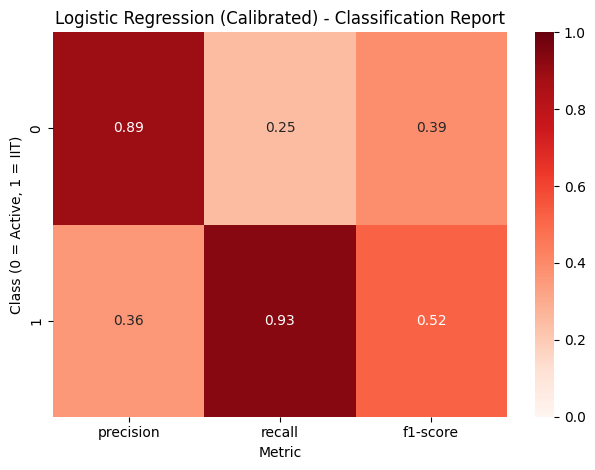

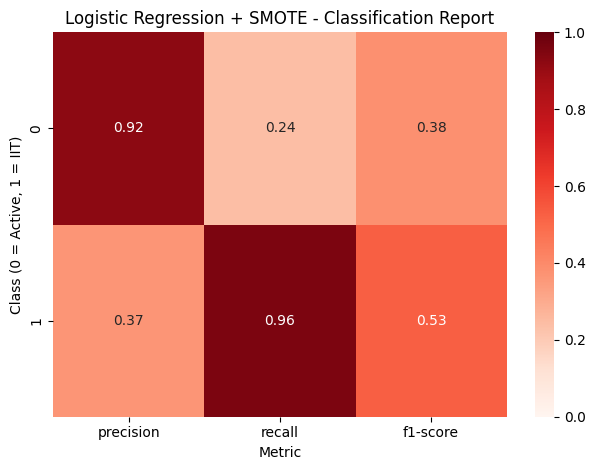

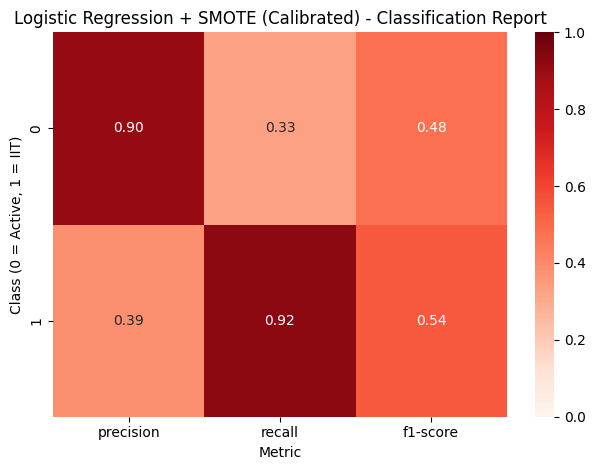

In [72]:
for model in models:
    generate_classification_report(model, testing_data)

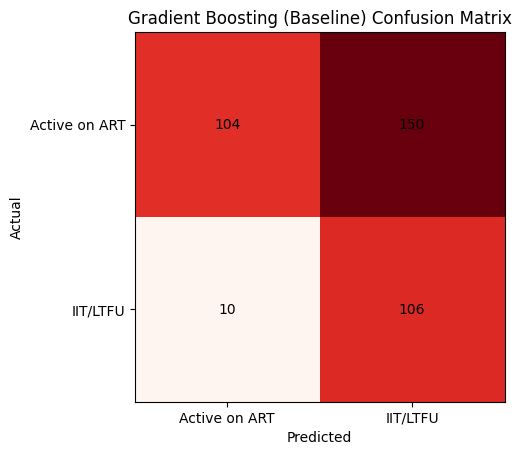

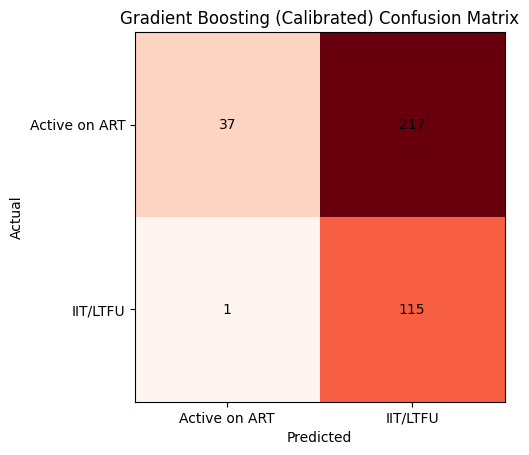

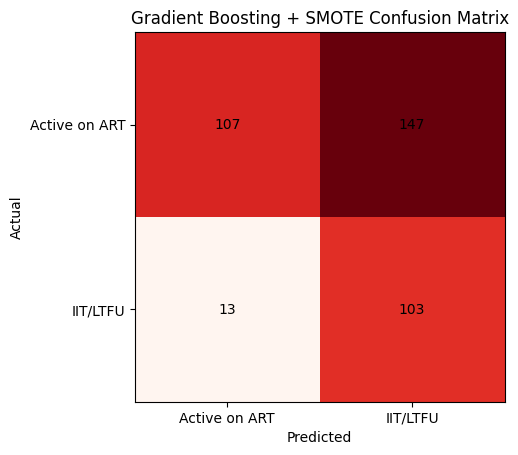

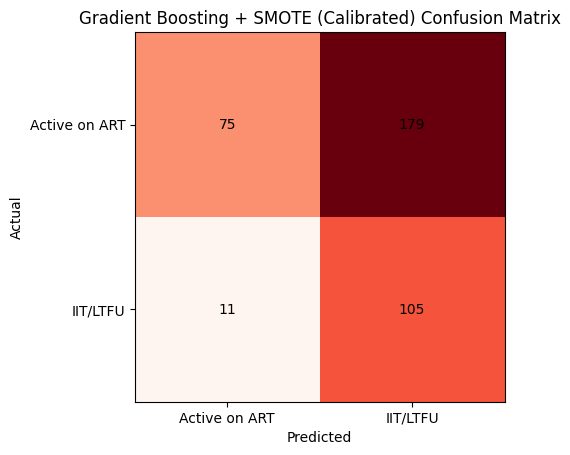

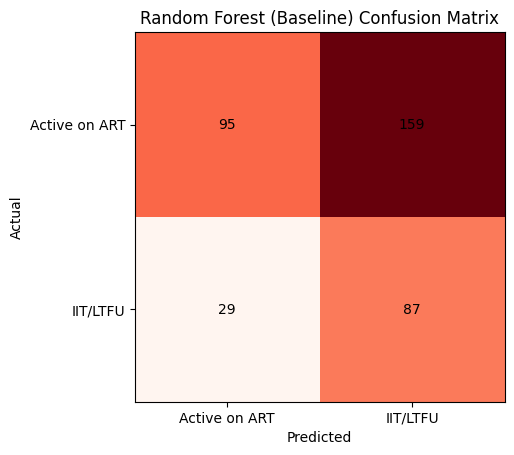

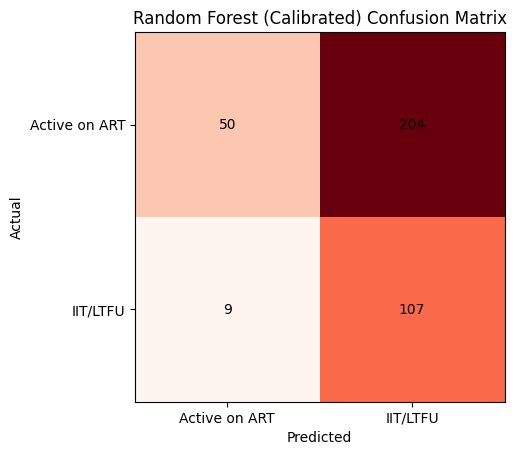

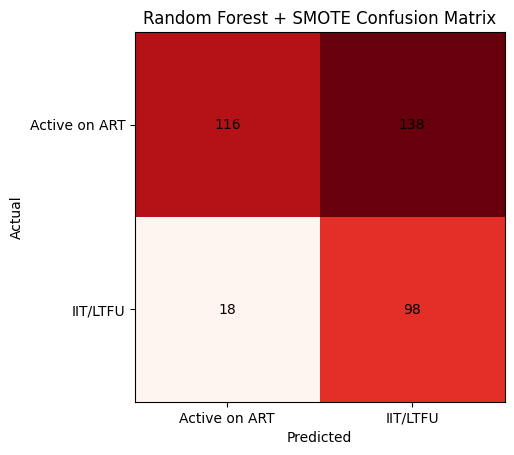

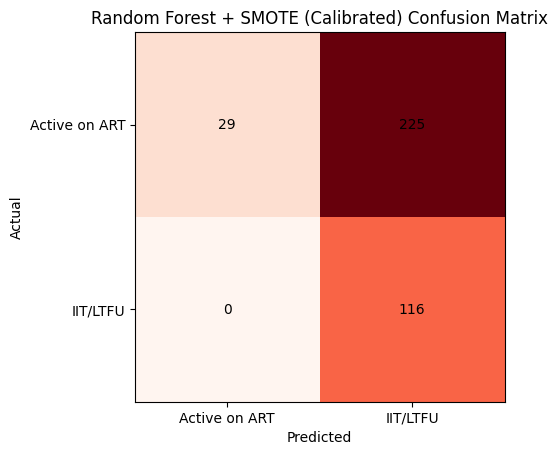

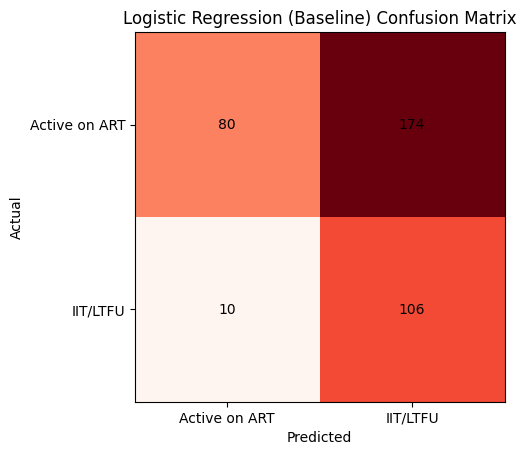

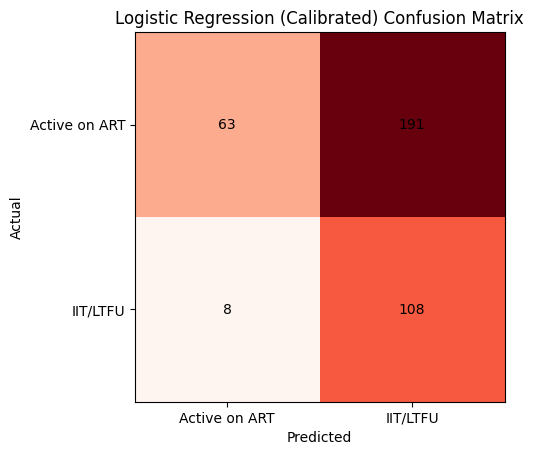

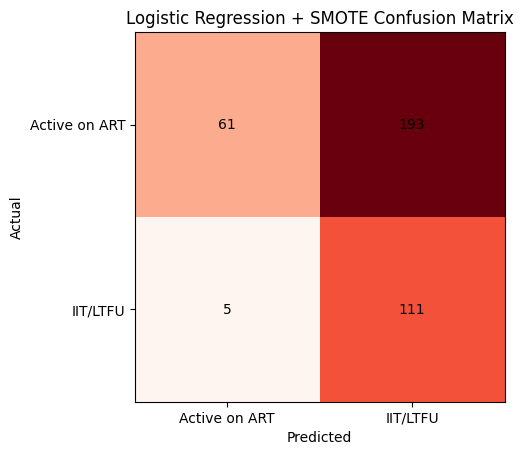

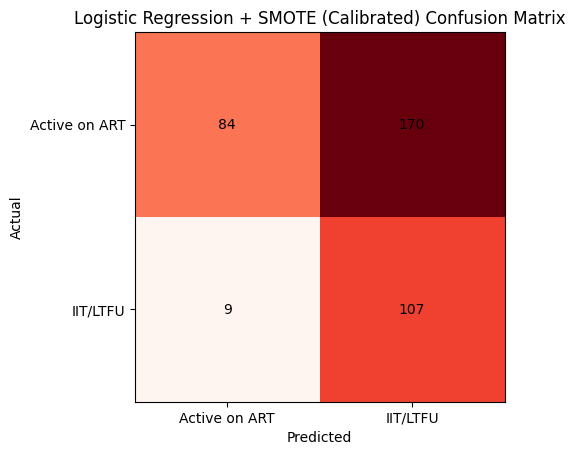

In [73]:
for model in models:
    plot_confusion_matrix(model, testing_data)

In [74]:
# import shap
# models_classifier = [
#           {'model': gboost_calibrated_model_sm, 'name': 'GBoost Calibrated'},
#           {'model': rf_calibrated_model_sm, 'name': 'Random Forest Calibrated'},
#           {'model': lr_calibrated_model_sm, 'name': 'Logistic Regression Calibrated'}]

# for model in models_classifier:
#     print(f"SHAP values for {model['name']}")
#     explainer = shap.Explainer(model['model'].predict_proba, trainning_data.drop('target', axis=1))
#     shap_values = explainer(testing_data.drop('target', axis=1))

#     shap.plots.scatter(shap_values[:,:,1][:, 'number_of_days_until_scheduled_drug_pickup'], color=shap_values[:,:,1])
#     plt.show()

#     shap.plots.bar(shap_values[:,:,1], max_display=10, show=False)
#     plt.show()

#     shap.plots.beeswarm(shap_values[:,:,1], max_display=10, show=False)
#     plt.show()

#     shap.plots.waterfall(shap_values[0,:,1])
#     plt.show()